# 05 · Role discovery

The comparison groups put a ball-playing centre-back next to a stopper, a winger who stays wide
next to one who cuts inside. The profiles (`02_player_profiles.ipynb`) say how well a player
plays the group's role; this notebook asks which role they play, from what they do and where.

1. **Which numbers describe a role.** Shares and places rather than volumes: where a player
   touches the ball, what they do with it, how they pass, with which foot, how they defend;
   whether each is stable over a season, and whether it belongs to the player or to their team.
2. **Roles or a continuum.** Whether the players of each comparison group fall into groups, and
   the axes along which they differ.
3. **Names and portraits.** What each axis opposes, on the pitch and in numbers, with the players
   at either end.
4. **Styles, the market and the back-test.** Whether the market paid differently by style, and
   where the shortlists of `04_recruitment_backtest.ipynb` fall.

**Players:** the 1,335 outfield players with a profile, in their comparison group, read from the
matches they played mainly in a position of that group.

**Data:** [StatsBomb Open Data](https://github.com/statsbomb/open-data) (events, lineups), 2015/16,
the four complete leagues. Only aggregated results are shown, as StatsBomb's licence requires.
Tables are built by `make model`; see `docs/DATA_DICTIONARY.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from mplsoccer import Pitch
from scipy.ndimage import gaussian_filter
from scipy.stats import rankdata
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from football_scouting.analysis.backtest import pick_weights
from football_scouting.analysis.leagues import team_effect
from football_scouting.analysis.market import (
    market_players,
    out_of_fold,
    profile_matrix,
    team_bootstrap,
    team_strength,
    value_model,
)
from football_scouting.analysis.metrics import OPEN_PLAY, TOUCH, in_box, player_match_counts
from football_scouting.analysis.outcomes import player_outcomes
from football_scouting.analysis.possession import player_possession
from football_scouting.analysis.profiles import (
    KEYS,
    POSSESSION,
    RELIABILITY_MINUTES,
    XPASS_SUMS,
    own_share,
    recording_context,
    recording_factors,
    rescale,
    value_sums,
)
from football_scouting.analysis.profiles import (
    LABELS as PROFILE_LABELS,
)
from football_scouting.analysis.reliability import split_half_reliability
from football_scouting.analysis.roles import (
    COVARIANCES,
    MIN_AXIS_RELIABILITY,
    MIN_CONGRUENCE,
    MIN_SHARE,
    MIN_STABILITY,
    bic,
    candidates,
    choose,
    congruence,
    fit,
    fit_axes,
    parallel_analysis,
    retained,
    shrink,
)
from football_scouting.analysis.style import (
    FAMILIES,
    IN_GROUP,
    LABELS,
    NAMES,
    SUMMED,
    adjust,
    descriptors,
    group_share,
    player_match_style,
    possession_slopes,
    touch_map,
)
from football_scouting.analysis.values import pool_valuations, value_at
from football_scouting.config import load_config
from football_scouting.model.database import connect_readonly
from football_scouting.plots import CREDIT, GREY, OKABE_ITO, credit, use_style

cfg = load_config()
con = connect_readonly(cfg)
use_style()

OUTFIELD = list(cfg.profiles)
GROUP_NAMES = {g.code: g.name for g in cfg.comparison_groups}
FAMILY_OF = {m: f for f, ms in FAMILIES.items() for m in ms}
YARDS = ["touch_height", "touch_width", "spread_length", "spread_width", "defence_height",
         "pass_length", "carry_distance"]  # fmt: skip


def lower(label):
    """A label in lower case, abbreviations (xG, xT) kept."""
    return label[0].lower() + label[1:]

## 1. Which numbers describe a role

A role is what a player does and where, not how much or how well. The candidates are therefore
shares and places, so that a player who is on the ball twice as often does not look like
another role (`analysis.style`):

- **where**: the mean height of a player's touches and their distance from the centre line (left
  and right alike), how far the touches spread along and across the pitch within a match, the
  height of the defensive actions, and the share of touches in the opposition box;
- **with the ball**: passes, dribbles and shots per touch, the distance carried per touch, and
  crosses per pass;
- **passing**: how easy the passes are (their mean expected completion, from
  `03_possession_value.ipynb`, section 3), their length, and the shares long, high, forward,
  backward, switches and through balls;
- **foot**: the share of passes with the left foot, and from the wide channels, the share played
  with the inside foot (the right foot on the left), the mark of a player who cuts inside;
- **without the ball**: pressures against tackles, interceptions, recoveries, clearances and
  blocks; tackles, and clearances with blocks, per defensive action; counterpressures and
  pressures in the final third per pressure; aerial duels per touch.

A style describes the role of a player's comparison group, so the candidates are read from the
matches a player spent at least half of in a position of their group: a centre-back's matches at
full-back describe another role, and a season split between two positions or two flanks would
otherwise pass for a style of its own. For the same reason the spreads are measured within each
match, so that changing flank between matches does not count. Counts StatsBomb recorded
differently between leagues and in the Premier League from match week 19 are first rescaled by
recording context, as in the profiles. Each candidate is judged within the comparison group, as
the profiles' statistics were:

- **reliability**: does a season's half describe the same player as the other half;
- **the player or the team**: how much the team explains, how much possession moves it within
  players, and whether it stays with a player who changes team;
- **what it repeats**: the other candidates and the profile.

### 1.1 The candidates

In [2]:
pool = con.sql("SELECT * FROM profile_players").df().set_index("player_id")
group = pool.comparison_group
rows = (
    player_match_counts(con)
    .merge(player_match_style(con), on=KEYS, validate="1:1")
    .merge(player_possession(con), on=KEYS, validate="1:1")
    .merge(value_sums(con, cfg, {"completion_above_expected"}), on=KEYS, how="left")
    .merge(group_share(con, cfg, group), on=KEYS, validate="1:1")
)
rows = rows[rows.player_id.isin(pool.index)].fillna(dict.fromkeys(XPASS_SUMS.values(), 0.0))
in_group = rows.group_share >= IN_GROUP
played = rows.groupby("player_id").minutes.sum()
outside_group = 1 - (rows.group_share * rows.minutes).groupby(rows.player_id).sum() / played
rows = rows[in_group]
context = recording_context(rows, cfg)
factors = recording_factors(rows, group, context, cfg.recording.statistics)
rows = rescale(rows, group, context, factors)
COLUMNS = [*SUMMED, "minutes", *POSSESSION]
season = rows.groupby("player_id")[COLUMNS].sum().loc[pool.index]
recorded = descriptors(season)
share = own_share(season)
minutes = season.minutes  # in the group's positions
regulars = pool.index[minutes >= cfg.compared.minutes]
print(
    f"Matches played mainly in a position of the player's group: {in_group.mean():.1%} of "
    f"player-matches, {minutes.sum() / played.sum():.1%} of minutes. Players with 900 minutes or "
    f"more in them: {len(regulars):,} (in all their matches: "
    f"{(pool.minutes >= cfg.compared.minutes).sum():,}); a fifth of their minutes or more "
    f"outside their group: {(outside_group.loc[regulars] >= 0.2).mean():.0%} of them."
)


def by_descriptor(d, columns=OUTFIELD):
    """Rows in family order, labelled; group columns named."""
    out = d.reindex(NAMES)[columns]
    out.index = pd.MultiIndex.from_arrays(
        [out.index.map(FAMILY_OF), out.index.map(LABELS)], names=["", ""]
    )
    return out.rename(columns=GROUP_NAMES).rename_axis(columns=None)


medians = recorded.groupby(group).median().T
table = by_descriptor(medians)
in_yards = [(FAMILY_OF[m], LABELS[m]) for m in YARDS]
styled = table.style.format("{:.1%}").format("{:.1f}", subset=pd.IndexSlice[in_yards, :])
display(styled.set_caption("Median of each candidate, players with a profile"))
print(
    f"{len(pool):,} players, {len(rows):,} player-matches; values missing (no attempt in the "
    f"season): {recorded.isna().sum().sum()}."
)

Matches played mainly in a position of the player's group: 88.3% of player-matches, 90.8% of minutes. Players with 900 minutes or more in them: 1,176 (in all their matches: 1,266); a fifth of their minutes or more outside their group: 14% of them.


1,335 players, 30,392 player-matches; values missing (no attempt in the season): 0.


**The candidates read like the positions.** Centre-backs touch the ball lowest (a median x of 40,
centre-forwards 79) and full-backs widest (29.5 yards from the centre line, central midfielders
17), though within a match a full-back's touches spread least across the pitch (10 yards): they
keep to their flank. Centre-forwards touch the ball most in the box (11% of their touches) and in
the air (8 aerial duels per 100 touches); attacking midfielders and wingers dribble and carry most
(2.5 dribbles per 100 touches, 2.0 yards carried per touch). Centre-backs pass longest (24 yards,
a quarter of their passes long) and most often forward (44%), centre-forwards most often backward
(24%, the lay-off). From the wide channels full-backs play 12% of their passes with the inside
foot, attacking midfielders, wingers and centre-forwards over half: full-backs stay on the side of
their foot, wingers often do not. Pressures are 39% of a centre-back's defensive engagements and
73% of a centre-forward's.

### 1.2 How reliable they are

Split-half reliability at 900 minutes within each group, as for the profiles: players with
1,800 minutes or more, their matches dealt at random into two halves of 900 minutes, values
centred within league, the correlation between halves averaged over 50 draws.

In [3]:
long_season = pool[minutes >= 2 * RELIABILITY_MINUTES]


def split_half(adjusted=False):
    """Reliability at 900 minutes of each candidate (rows) in each group (columns)."""
    out = {}
    for g in OUTFIELD:
        ids = long_season.index[long_season.comparison_group == g]

        def rate_fn(s, g=g):
            values = descriptors(s)
            if adjusted:
                values = adjust(values, own_share(s), pd.Series(g, index=s.index), slopes)
            return values

        curve = split_half_reliability(
            rows[rows.player_id.isin(ids)], long_season.league.loc[ids], NAMES,
            [RELIABILITY_MINUTES], columns=COLUMNS, rate_fn=rate_fn,
        )  # fmt: skip
        out[g] = curve[NAMES].mean()
    return pd.DataFrame(out)


reliability = split_half()
profile_reliability = (
    con.sql(
        "SELECT comparison_group, median(reliability) AS r FROM profile_statistics GROUP BY ALL"
    )
    .df()
    .set_index("comparison_group")
    .r
)
print(
    "Median reliability at 900 minutes, candidates against the profile's twelve statistics: "
    + "; ".join(
        f"{GROUP_NAMES[g].lower()} {reliability[g].median():.2f} against "
        f"{profile_reliability[g]:.2f}"
        for g in OUTFIELD
    )
    + ". Below 0.5: "
    + "; ".join(
        f"{GROUP_NAMES[g].lower()}: "
        + ", ".join(lower(LABELS[m]) for m in reliability.index[reliability[g] < 0.5])
        for g in OUTFIELD
        if (reliability[g] < 0.5).any()
    )
    + "."
)

Median reliability at 900 minutes, candidates against the profile's twelve statistics: centre-backs 0.62 against 0.61; full-backs 0.72 against 0.68; central midfielders 0.79 against 0.70; attacking midfielders and wingers 0.80 against 0.71; centre-forwards 0.68 against 0.68. Below 0.5: centre-backs: dribbles per touch, shots per touch, crosses per pass, through balls per pass, tackles per defensive action, counterpressures per pressure, final-third pressures per pressure; full-backs: through balls per pass, counterpressures per pressure, final-third pressures per pressure; central midfielders: through balls per pass, counterpressures per pressure; attacking midfielders and wingers: tackles per defensive action, counterpressures per pressure; centre-forwards: switches per pass, through balls per pass, tackles per defensive action, counterpressures per pressure.


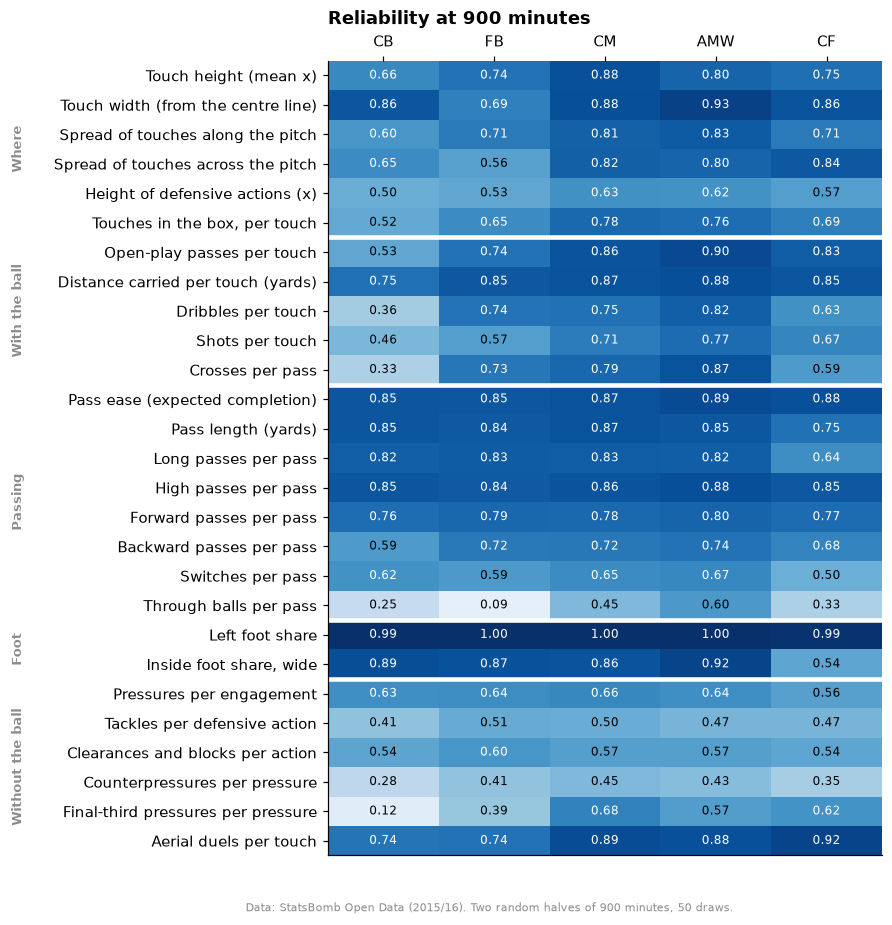

In [4]:
def heatmap(ax, values, title, vmin=0, vmax=1, cmap="Blues", fmt="{:.2f}"):
    """Candidates (rows, by family) against groups (columns), each cell labelled."""
    v = values.reindex(NAMES)[OUTFIELD]
    ax.imshow(v.to_numpy(), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    for (i, j), x in np.ndenumerate(v.to_numpy()):
        dark = (x - vmin) / (vmax - vmin) > 0.6
        ax.text(j, i, fmt.format(x), ha="center", va="center", fontsize=8,
                color="white" if dark else "black")  # fmt: skip
    ax.set_xticks(range(len(OUTFIELD)), OUTFIELD)
    ax.xaxis.tick_top()
    ax.set_yticks(range(len(NAMES)), [LABELS[m] for m in NAMES])
    ax.grid(False)
    edges = np.cumsum([len(ms) for ms in FAMILIES.values()])[:-1] - 0.5
    for e in edges:
        ax.axhline(e, color="white", lw=3)
    ax.set_title(title, pad=24)


fig, ax = plt.subplots(figsize=(6.5, 8.5))
fig.subplots_adjust(bottom=0.03)
heatmap(ax, reliability, "Reliability at 900 minutes")
start = 0
for family, members in FAMILIES.items():
    ax.text(-0.56, start + (len(members) - 1) / 2, family, transform=ax.get_yaxis_transform(),
            rotation=90, ha="center", va="center", fontsize=8.5, color=GREY,
            fontweight="bold")  # fmt: skip
    start += len(members)
credit(fig, "Data: StatsBomb Open Data (2015/16). Two random halves of 900 minutes, 50 draws.")
plt.show()

**Style is at least as stable as output.** The candidates' median reliability at 900 minutes is
0.62 to 0.80 by group, against 0.61 to 0.71 for the profiles' statistics: higher among
full-backs, central midfielders and attacking midfielders and wingers (0.72 to 0.80, against 0.68
to 0.71), the same among centre-backs (0.62 against 0.61) and centre-forwards (0.68 both). The
foot a player passes with is fixed (0.99 to 1.00), and how they pass (ease, length, high and
forward passes) reaches 0.75 to 0.89 in every group. Read in their own position, centre-backs
differ least: where they touch the ball, how high they defend and how often they pass sit at 0.50
to 0.66, apart from their width (0.86); their carrying reaches 0.75. Below 0.5: through balls
(rare outside attacking midfielders and wingers), counterpressures per pressure, tackles per
defensive action among centre-backs, attacking midfielders and wingers and centre-forwards,
final-third pressures among defenders, switches among centre-forwards, and among centre-backs
dribbles, shots and crosses, actions they rarely make in their own position.

### 1.3 The player or the team

A role can belong to the team more than to the player: a centre-back plays short passes because
their team builds from the back, a full-back defends high because their team has the ball. Three
checks:

- **the team's share** of each candidate among the group's regulars (900 minutes or more),
  beyond what 80 teams explain by chance (`leagues.team_effect`);
- **possession within players**: how a player's value moves from match to match with their team's
  share of the ball (a weighted least-squares slope with a fixed effect per player, fitted on the
  regulars, `style.possession_slopes`), and the candidates put on an even share by it;
- **players who changed team** in January, with 450 minutes or more at each of two pool teams:
  how far their values at one team predict those at the other, against what the candidates'
  reliability would allow if nothing had changed.

In [5]:
slopes = possession_slopes(rows, group.loc[regulars])
adjusted = adjust(recorded, share, group, slopes)
main_team = (
    rows.groupby(["player_id", "team_id"]).minutes.sum().reset_index()
    .sort_values(["minutes", "team_id"]).groupby("player_id").tail(1)
    .set_index("player_id").team_id
)  # fmt: skip


def team_and_possession(values):
    """Team share and Spearman correlation with possession, regulars, per group."""
    team, with_possession = {}, {}
    for g in OUTFIELD:
        ids = regulars[group.loc[regulars] == g]
        frame = values.loc[ids].assign(team=main_team.loc[ids], group=g)
        team[g] = pd.Series({m: team_effect(frame, m) for m in NAMES})
        with_possession[g] = values.loc[ids].corrwith(share.loc[ids], method="spearman")
    return pd.DataFrame(team), pd.DataFrame(with_possession)


team_recorded, poss_recorded = team_and_possession(recorded)
team_adjusted, poss_adjusted = team_and_possession(adjusted)
in_yards = [(FAMILY_OF[m], LABELS[m]) for m in YARDS]
display(
    by_descriptor(slopes.T / 10)
    .style.format("{:+.3f}")
    .format("{:+.1f}", subset=pd.IndexSlice[in_yards, :])
    .set_caption("Change per 10 points of the team's possession, within players")
)


def arrows(before, after):
    return (
        by_descriptor(before).round(2).astype(str)
        + " → "
        + by_descriptor(after).round(2).astype(str)
    )


display(
    arrows(poss_recorded, poss_adjusted).style.set_caption(
        "Correlation with the team's possession (Spearman), as recorded → on an even share"
    )
)
display(
    arrows(team_recorded, team_adjusted).style.set_caption(
        "The team's share beyond chance, as recorded → on an even share"
    )
)

In [6]:
reliability_adjusted = split_half(adjusted=True)
change = reliability_adjusted - reliability
print(
    "Reliability on an even share of possession: a median change of "
    f"{change.stack().median():+.3f}, the largest loss {change.stack().min():+.2f} "
    f"({lower(LABELS[change.min(axis=1).idxmin()])}, "
    f"{GROUP_NAMES[change.min().idxmin()].lower()}). Groups where the team's share falls by 0.10 "
    "or more: "
    + ", ".join(
        f"{lower(LABELS[m])} {n}"
        for m, n in (team_recorded - team_adjusted).ge(0.1).sum(axis=1).items()
        if n
    )
    + "."
)

Reliability on an even share of possession: a median change of -0.002, the largest loss -0.16 (counterpressures per pressure, attacking midfielders and wingers). Groups where the team's share falls by 0.10 or more: spread of touches along the pitch 1, height of defensive actions (x) 3, pass ease (expected completion) 2, high passes per pass 2, forward passes per pass 2, clearances and blocks per action 1, counterpressures per pressure 4, final-third pressures per pressure 3.


**Possession moves places and pressing; the team keeps part of its passing style.**

- Within players, ten more points of possession raise touches by 2.3 to 3.8 yards and defensive
  actions by 3.6 to 5.9 yards, add 3 to 4 counterpressures per 100 pressures, and make
  defenders' passes easier and less often high or forward (centre-backs: 2.6 points more expected
  completion, 3.6 fewer high passes per 100; full-backs: 4.4 fewer forward passes per 100).
- On an even share, touch height, the height of defensive actions, clearances and blocks,
  counterpressures and final-third pressures no longer follow the team's possession (from 0.15
  to 0.55 in absolute value to at most 0.24; the centre-forwards' slopes overshoot slightly).
  Passing style still does: pass ease at 0.48 to 0.52 among defenders and central midfielders,
  high passes at −0.48 to −0.55, aerial duels per touch at −0.25 to −0.43.
- The team's share is 0.4 or more for how defenders pass (pass ease and high passes among
  centre-backs, 0.47 and 0.48, and full-backs, 0.49 and 0.44; pass ease among central
  midfielders, 0.41), for centre-backs' aerial duels (0.52), and for where defenders play:
  centre-backs' touch height and spreads (0.40 to 0.43), full-backs' touch height (0.50), width
  (0.41) and forward passes (0.42). How a team builds, how high its line stands and how opponents
  attack it, more than the player. Elsewhere it is at most 0.39.
- The adjustment costs no reliability (a median change of −0.002).

In [7]:
stints = rows.groupby(["player_id", "team_id"])[COLUMNS].sum()
stints = stints[stints.minutes >= 450]
moved = stints.groupby(level="player_id").size().loc[lambda n: n >= 2].index
stints = stints.loc[moved].sort_values("minutes", ascending=False)
first = stints.groupby(level="player_id").head(1).droplevel("team_id").sort_index()
second = stints.groupby(level="player_id").nth(1).droplevel("team_id").sort_index()
mover_group = group.loc[first.index]


def at_team(s, adjusted):
    values = descriptors(s)
    if adjusted:
        values = adjust(values, own_share(s), mover_group, slopes)
    return values - values.groupby(mover_group).transform("mean")


rng = np.random.default_rng(2016)
draws = [rng.integers(0, len(first), len(first)) for _ in range(1000)]
carry = []
for version, rel in (("as recorded", reliability), ("even share", reliability_adjusted)):
    a, b = at_team(first, version == "even share"), at_team(second, version == "even share")
    k = RELIABILITY_MINUTES * (1 - rel) / rel  # minutes at which a candidate is half signal
    for m in NAMES:
        km = k.loc[m].reindex(mover_group).to_numpy()
        expected = np.sqrt(
            first.minutes / (first.minutes + km) * second.minutes / (second.minutes + km)
        ).mean()
        x, y = a[m].to_numpy(), b[m].to_numpy()
        boot = [np.corrcoef(x[i], y[i])[0, 1] for i in draws]
        carry.append({
            "version": version, "candidate": m, "expected": expected,
            "observed": np.corrcoef(x, y)[0, 1],
            "low": np.nanpercentile(boot, 5), "high": np.nanpercentile(boot, 95),
        })  # fmt: skip
carry = pd.DataFrame(carry)
carry["kept"] = carry.observed / carry.expected
print(
    f"{len(first)} players with 450+ minutes at two pool teams ("
    + ", ".join(f"{GROUP_NAMES[g].lower()} {n}" for g, n in mover_group.value_counts().items())
    + f"), a median {first.minutes.median():,.0f} and {second.minutes.median():,.0f} minutes. "
    "Share of the expected correlation kept, median over the candidates: "
    + ", ".join(f"{v} {c.kept.median():.2f}" for v, c in carry.groupby("version", sort=False))
    + "."
)

22 players with 450+ minutes at two pool teams (central midfielders 6, attacking midfielders and wingers 5, centre-forwards 5, centre-backs 4, full-backs 2), a median 1,116 and 703 minutes. Share of the expected correlation kept, median over the candidates: as recorded 0.80, even share 0.76.


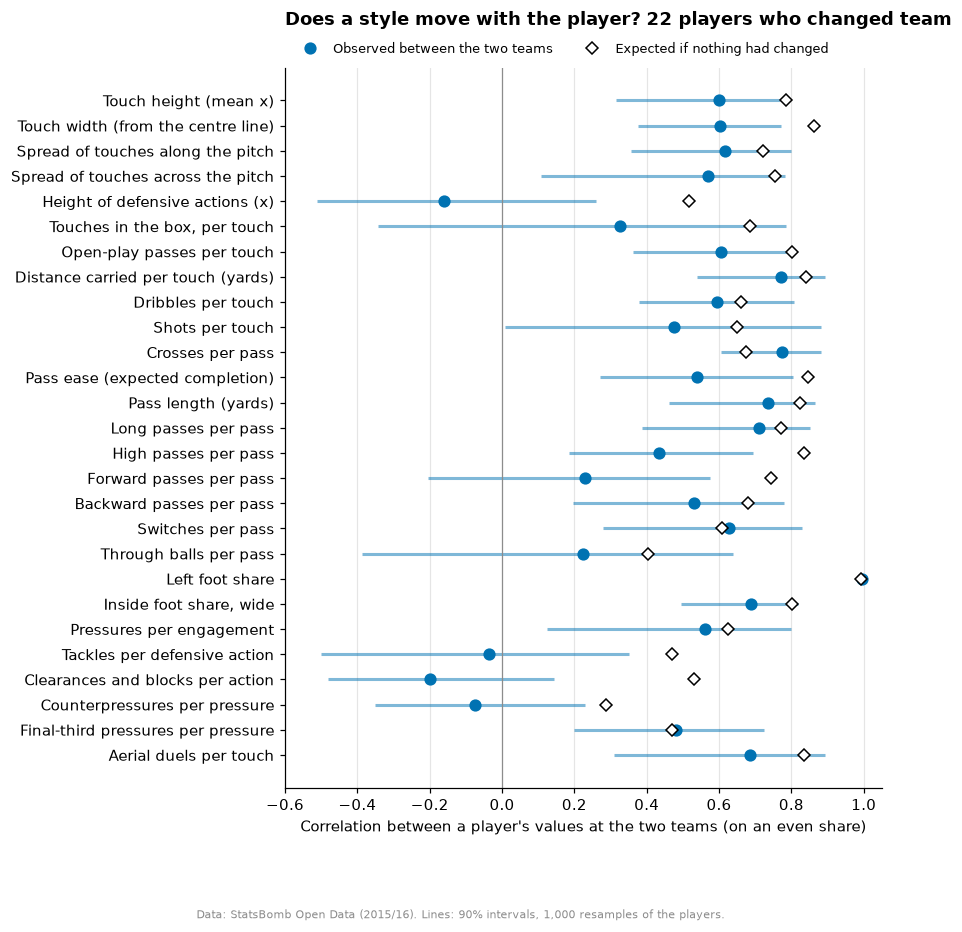

In [8]:
even = carry[carry.version == "even share"].set_index("candidate").reindex(NAMES)
fig, ax = plt.subplots(figsize=(7, 8.5))
ypos = np.arange(len(NAMES))
ax.hlines(ypos, even.low, even.high, color=OKABE_ITO[0], lw=2, alpha=0.5)
ax.plot(even.observed, ypos, "o", color=OKABE_ITO[0], ms=7, label="Observed between the two teams")
ax.plot(even.expected, ypos, "D", mfc="white", mec="black", ms=6,
        label="Expected if nothing had changed")  # fmt: skip
ax.set_yticks(ypos, [LABELS[m] for m in NAMES])
ax.invert_yaxis()
ax.axvline(0, color=GREY, lw=0.8)
ax.set_xlim(-0.6, 1.05)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Correlation between a player's values at the two teams (on an even share)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=8.5)
ax.set_title(f"Does a style move with the player? {len(first)} players who changed team", pad=28)
credit(fig, "Data: StatsBomb Open Data (2015/16). Lines: 90% intervals, 1,000 resamples of the "
            "players.")  # fmt: skip
plt.show()

**Most of a style moves with the player; how they defend does not.** The 22 players who changed
team in January, most of them midfielders and forwards, kept about three quarters of the
correlation their numbers would have kept had nothing changed (a median of 0.76 over the
candidates on an even share, 0.80 as recorded). Their foot (1.00), their carrying (0.92), the
length of their passes (0.89), their crossing and their switches of play (as much as their
reliability allows) went with them; the height of their defensive actions (−0.31), their
clearances and blocks (−0.37), their tackles and counterpressures (below 0) and the share of
their passes played forward (0.31) did not. Twenty-two players make wide intervals, and a player
who moves is often used differently, so this reads as a direction rather than a measure.

### 1.4 What the candidates repeat

Within each group, among the regulars: pairs of candidates that rank players alike (Spearman
0.8 or more, the profiles' limit), the profile statistic each candidate follows most closely,
and what the profile's own main axis measures: the first principal component of the twelve
statistics (shrunk, standardised), set against the team's strength, its possession, the
player's market value on 30 June 2016 and their minutes.

In [9]:
pairs = []
for g in OUTFIELD:
    ids = regulars[group.loc[regulars] == g]
    c = adjusted.loc[ids].corr(method="spearman")
    for i, a in enumerate(NAMES):
        for b in NAMES[i + 1 :]:
            if abs(c.loc[a, b]) >= 0.8:
                pairs.append((GROUP_NAMES[g], LABELS[a], LABELS[b], c.loc[a, b]))
display(
    pd.DataFrame(pairs, columns=["Group", "Candidate", "Candidate ", "Spearman"])
    .style.format("{:+.2f}", subset="Spearman").hide(axis="index")
    .set_caption("Pairs of candidates at 0.8 or more, on an even share")
)  # fmt: skip

shrunk = (
    con.sql("SELECT player_id, statistic, shrunk FROM profile_values")
    .df()
    .pivot(index="player_id", columns="statistic", values="shrunk")
)
closest = {}
for g, statistics in cfg.profiles.items():
    ids = regulars[group.loc[regulars] == g]
    c = pd.concat([adjusted.loc[ids], shrunk.loc[ids, list(statistics)]], axis=1)
    c = c.corr(method="spearman").loc[NAMES, list(statistics)].abs()
    closest[g] = (
        c.max(axis=1).map("{:.2f}".format)
        + " "
        + c.idxmax(axis=1).map(lambda s: lower(PROFILE_LABELS[s]))
    )
display(
    by_descriptor(pd.DataFrame(closest)).style.set_caption(
        "The profile statistic each candidate follows most closely (|Spearman|)"
    )
)

Group,Candidate,Candidate,Spearman
Centre-backs,"Touches in the box, per touch",Shots per touch,+0.85
Centre-backs,Pass ease (expected completion),High passes per pass,-0.92
Centre-backs,Pass length (yards),Long passes per pass,+0.97
Full-backs,Pass ease (expected completion),High passes per pass,-0.90
Full-backs,Pass length (yards),Long passes per pass,+0.96
Central midfielders,Pass ease (expected completion),High passes per pass,-0.83
Central midfielders,Pass length (yards),Long passes per pass,+0.96
Attacking midfielders and wingers,Open-play passes per touch,Dribbles per touch,-0.83
Attacking midfielders and wingers,Pass ease (expected completion),High passes per pass,-0.81
Attacking midfielders and wingers,Pass length (yards),Long passes per pass,+0.95


In [10]:
strength = team_strength(con).set_index("team_id").goal_difference
value = value_at(pool_valuations(con), cfg.backtest.market_view).value
axes = []
for g, statistics in cfg.profiles.items():
    ids = pool.index[group == g]
    x = shrunk.loc[ids, list(statistics)]
    pca = PCA().fit((x - x.mean()) / x.std())
    score = pd.Series(pca.transform((x - x.mean()) / x.std())[:, 0], index=ids)
    loading = pd.Series(pca.components_[0], index=list(statistics))
    if loading.sum() < 0:
        score, loading = -score, -loading
    top = loading.sort_values()
    axes.append({
        "Group": GROUP_NAMES[g],
        "PC1": pca.explained_variance_ratio_[0],
        "PC2": pca.explained_variance_ratio_[1],
        "Highest loadings": ", ".join(lower(PROFILE_LABELS[s]) for s in top.index[::-1][:3]),
        "Lowest loadings": ", ".join(lower(PROFILE_LABELS[s]) for s in top.index[:3]),
        "Team's goal difference": score.corr(main_team.loc[ids].map(strength), method="spearman"),
        "Possession": score.corr(share.loc[ids], method="spearman"),
        "Log value": score.corr(np.log(value.reindex(ids)), method="spearman"),
        "Minutes": score.corr(pool.minutes.loc[ids], method="spearman"),
    })  # fmt: skip
display(
    pd.DataFrame(axes).style.hide(axis="index")
    .format("{:.0%}", subset=["PC1", "PC2"])
    .format("{:+.2f}", subset=["Team's goal difference", "Possession", "Log value", "Minutes"])
    .set_caption("The profile's first principal component, and what it follows (Spearman)")
)  # fmt: skip

Group,PC1,PC2,Highest loadings,Lowest loadings,Team's goal difference,Possession,Log value,Minutes
Centre-backs,26%,19%,"progressive passes (zones), open-play passes, long passes (30+ yards)","aerial duels, clearances, ball losses per touch",+0.08,+0.17,+0.08,+0.24
Full-backs,33%,17%,"completed passes into the box, progressive carries (zones), key passes (open play)","pass completion above expected, tackles, pressures",+0.02,+0.08,+0.28,+0.13
Central midfielders,27%,20%,"long passes (30+ yards), open-play passes, progressive passes (zones)","ball losses per touch, non-penalty xG, progressive carries (zones)",+0.06,+0.10,+0.02,+0.15
Attacking midfielders and wingers,22%,19%,"progressive carries (zones), dribbles attempted, completed passes into the box","tackles, pressures, non-penalty xG per shot",+0.15,+0.15,+0.31,+0.16
Centre-forwards,22%,20%,"xT gained, dribbles attempted, open-play passes","aerial duels, aerial duels won, ball losses per touch",+0.28,+0.24,+0.37,+0.21


**What the candidates repeat.**

- Pass length and the share of long passes are the same number in every group (0.92 to 0.97),
  and pass ease mirrors high passes in every group (−0.81 to −0.92). Three more pairs belong to
  one group: centre-backs' touches in the box and shots (0.85, both from set pieces), attacking
  midfielders' and wingers' passes and dribbles per touch (−0.83), centre-forwards' touch width
  and spread across the pitch (0.94).
- The shares of actions follow the profile's counts per 90, as a player's touches vary less
  than their actions: dribbles per touch and dribbles (0.90 to 0.96 among full-backs, attacking
  midfielders, wingers and centre-forwards), tackles per defensive action and tackles (0.84 to
  0.90 outside centre-forwards), crosses per pass and crosses (0.91, 0.93 among full-backs and
  attacking midfielders and wingers). The foot and the shape of a player's game are new: the
  foot follows no profile statistic above 0.42, the spreads and the shares of forward and
  backward passes none above 0.56.
- **The profile's first principal component is not how good a player is.** It holds 22% to 33%
  of the variation in the twelve statistics, and follows the team's goal difference at 0.02 to
  0.28, its possession at 0.08 to 0.24 and the player's market value at 0.02 to 0.37. Its
  loadings set two ways of playing the position against each other: centre-backs who pass
  against those who head and clear, full-backs who supply the box and carry against those who
  tackle and press, central midfielders who pass long against those who carry and shoot,
  attacking midfielders and wingers who carry and dribble against those who press and tackle,
  centre-forwards who link play (xT, dribbles, passes) against those who win headers.

### 1.5 The descriptors chosen

Roles are found from the descriptors themselves rather than from the profile: they are more
reliable, they add where a player plays, the shape of their passing and their foot, and they
leave the profile free to judge how well a role is played. Each is put on an even share of
possession by its slope within players, and each group keeps those that pass three rules:

- **reliable**: 0.5 or more at 900 minutes, so that at the minutes players are compared from, at
  least half of the differences between them are real;
- **the player's more than the team's**: the team explains less than 0.4 beyond chance (pass
  completion, which left the profiles as a team number, stood at 0.41 to 0.60 among defenders and
  central midfielders);
- **no repeat**: of two descriptors at a Spearman correlation of 0.8 or more, the profiles'
  limit, the more reliable stays.

The share of passes with the left foot stays out: it says which side a player plays, not which
role. The inside foot can say the same: a right-footed player put on the left passes with the
inside foot from the wide channels without choosing to. It stays out of a group where the flank
a player is put on, given their foot, explains half of it or more (R², regulars who played on a
flank), except among attacking midfielders and wingers, where the side of the other foot is the
role itself: the inverted winger who cuts inside. The descriptors chosen are `roles.descriptors`
in `config/pipeline.yaml`.

In [11]:
positions = (
    con.sql(
        "SELECT match_id, team_id, player_id, position, sum(seconds) / 60 AS minutes "
        "FROM player_positions GROUP BY ALL"
    )
    .df()
    .merge(rows[KEYS], on=KEYS)
)  # the matches the descriptors are read from
flank = positions.position.str.split().str[0].where(lambda w: w.isin(["Left", "Right"]))
by_flank = (
    positions.assign(flank=flank)
    .pivot_table(index="player_id", columns="flank", values="minutes", aggfunc="sum")
    .reindex(pool.index).fillna(0)
)  # fmt: skip
on_flank = by_flank.Left + by_flank.Right
left_footed = recorded.left_foot_share > 0.5
other_side = by_flank.Right.where(left_footed, by_flank.Left) / on_flank.replace(0, np.nan)
side_r2, flanked = {}, {}
for g in OUTFIELD:
    ids = regulars[(group.loc[regulars] == g).to_numpy() & (on_flank.loc[regulars] > 0).to_numpy()]
    side_r2[g] = adjusted.loc[ids, "inside_foot_share"].corr(other_side.loc[ids]) ** 2
    flanked[g] = len(ids)
print(
    "The inside foot explained by the flank of the other foot (R², regulars who played on a "
    "flank): "
    + "; ".join(f"{GROUP_NAMES[g].lower()} {side_r2[g]:.2f} ({flanked[g]})" for g in OUTFIELD)
    + "."
)

The inside foot explained by the flank of the other foot (R², regulars who played on a flank): centre-backs 0.88 (250); full-backs 0.81 (240); central midfielders 0.68 (283); attacking midfielders and wingers 0.80 (253); centre-forwards 0.03 (148).


In [12]:
MIN_RELIABILITY, MAX_TEAM, MAX_PAIR, MAX_SIDE = 0.5, 0.4, 0.8, 0.5
ROLE_SIDE = {"AMW"}  # where the side of the other foot is the role: the inverted winger
chosen, verdicts = {}, {}
for g in OUTFIELD:
    ids = regulars[group.loc[regulars] == g]
    c = adjusted.loc[ids].corr(method="spearman").abs()
    rel, team = reliability_adjusted[g], team_adjusted[g]
    verdict = pd.Series("", index=NAMES)
    verdict[team >= MAX_TEAM] = team.map("team {:.2f}".format)
    verdict[rel < MIN_RELIABILITY] = rel.map("reliability {:.2f}".format)
    verdict["left_foot_share"] = "a side"
    if side_r2[g] >= MAX_SIDE and g not in ROLE_SIDE:
        verdict["inside_foot_share"] = f"a side (R² {side_r2[g]:.2f})"
    kept = []
    for m in rel[verdict == ""].sort_values(ascending=False).index:  # the more reliable first
        twin = next((o for o in kept if c.loc[m, o] >= MAX_PAIR), None)
        if twin is None:
            kept.append(m)
        else:
            verdict[m] = f"{c.loc[m, twin]:.2f} with {lower(LABELS[twin]).split(' (')[0]}"
    chosen[g] = [m for m in NAMES if m in kept]
    verdicts[g] = verdict.replace("", "✓")
assert chosen == {g: list(ms) for g, ms in cfg.roles.descriptors.items()}  # as configured
display(
    by_descriptor(pd.DataFrame(verdicts)).style.set_caption(
        "The descriptors each group's roles are found from (✓), and why the others stay out"
    )
)
print(
    "Descriptors chosen: "
    + ", ".join(f"{GROUP_NAMES[g].lower()} {len(ms)}" for g, ms in chosen.items())
    + "."
)

Descriptors chosen: centre-backs 9, full-backs 16, central midfielders 21, attacking midfielders and wingers 20, centre-forwards 19.


**Nine to twenty-one descriptors per group.**

- Reliability leaves out actions a group rarely makes: through balls (outside attacking
  midfielders and wingers), counterpressures, tackles per defensive action (among centre-backs,
  attacking midfielders and wingers and centre-forwards), final-third pressures (outside central
  midfielders and centre-forwards), switches among centre-forwards (0.49), and among centre-backs
  dribbles, shots and crosses (0.36, 0.45, 0.33), the height of their defensive actions (0.39)
  and their clearances and blocks (0.48).
- The team rule leaves out where defenders play and how they pass: centre-backs' touch height
  and spreads (0.40 to 0.43), full-backs' touch height (0.50), width (0.41) and forward passes
  (0.42), pass ease and high passes among both (0.44 to 0.49), central midfielders' pass ease
  (0.41) and centre-backs' aerial duels per touch (0.52).
- The inside foot leaves centre-backs, full-backs and central midfielders as a side (R² 0.88,
  0.81 and 0.68) and stays for attacking midfielders and wingers (0.80, the inverted winger) and
  centre-forwards, whose flank explains none of it (0.03).
- Pass length stands for the share of long passes in every group, pass ease for high passes
  among attacking midfielders and wingers and centre-forwards, passes per touch for dribbles
  among attacking midfielders and wingers, and touch width for the spread across the pitch among
  centre-forwards.
- Centre-backs keep nine: how wide they stand, how often they reach the box, how they use the
  ball (passes per touch, carrying, the length and direction of their passes, switches) and how
  often they press rather than tackle or clear.
- The height of defensive actions, clearances and blocks and tackles per defensive action pass
  the rules in some groups though they did not move with the 22 players who changed team. They
  stay: 22 players cannot settle it, and section 2 measures how much of each axis the team
  explains.

### What section 1 shows

- **Style is at least as stable as output**: a median reliability of 0.62 to 0.80 at 900 minutes,
  against 0.61 to 0.71 for the profiles' statistics; higher in midfield and on the wings, the
  same for centre-backs and centre-forwards.
- **A style is read from a player's own position**: the matches they spent mainly in a position
  of their group (88% of player-matches, 91% of minutes), with spreads measured within each
  match, so that a season split between positions or flanks does not pass for a style.
- **Possession moves where a player plays and how they press.** Put on an even share by their
  slope within players, those numbers no longer follow possession, at no cost in reliability.
- **Where defenders play and how they pass is partly the team's**: centre-backs' and full-backs'
  touch height, pass ease and high passes, centre-backs' spreads and aerial duels keep a team
  share of 0.40 to 0.52 on an even share.
- **Most of a style moves with a player who changes team**: 22 players kept three quarters of
  what their numbers' reliability allowed; their foot, carrying, crossing and passing length
  moved with them, how high and how they defended did not.
- **The profile's main axis is already a role**: it sets two ways of playing each position
  against each other and barely follows the team's strength or the player's value.
- **Style is read from 9 to 21 descriptors per group**, on an even share of possession: each
  reliable (0.5 or more at 900 minutes), the player's more than the team's (a team share under
  0.4), none repeating another. Defenders' places and passing style stay out as the team's; the
  left foot stays out as a side, and so does the inside foot outside attacking midfielders,
  wingers and centre-forwards.

## 2. Roles or a continuum

Each group's descriptors (section 1.5), on an even share of possession, are first shrunk towards
the group's mean by their reliability, as the profiles' statistics are: weight M / (M + K), with
M the player's minutes and K = 900 (1 − r) / r from the reliability r on an even share (section
1.3), so that a short season does not make an extreme style by chance. Roles are fitted on each
group's regulars (900 minutes or more), and every profiled player is then placed on them
(`analysis.roles`). Two readings, each under a rule fixed before any result was seen:

1. **Roles as groups**: a Gaussian mixture, each player with a probability of each role.
2. **Style axes**: the directions in which the group's players differ, each player with a score
   on each.

Then **the axes, the positions and the team**: what the positions StatsBomb records and the
team explain of them.

In [13]:
half_signal = RELIABILITY_MINUTES * (1 - reliability_adjusted) / reliability_adjusted
shrunk = shrink(adjusted, minutes, group, half_signal)
DESCRIPTORS = {g: list(ms) for g, ms in cfg.roles.descriptors.items()}
fitted = {g: shrunk.loc[regulars[group.loc[regulars] == g], ms] for g, ms in DESCRIPTORS.items()}
median_k = pd.Series({g: half_signal.loc[ms, g].median() for g, ms in DESCRIPTORS.items()})
own_weight = minutes / (minutes + group.map(median_k))
print(
    "Regulars the roles are fitted on: "
    + ", ".join(f"{GROUP_NAMES[g].lower()} {len(x)}" for g, x in fitted.items())
    + f"; {len(pool) - len(regulars)} players with fewer minutes are placed on them. Median K "
    + f"{median_k.min():.0f} to {median_k.max():.0f} minutes by group: a player keeps a median "
    + f"{own_weight.loc[regulars].median():.0%} of their own values (the others "
    + f"{own_weight.drop(regulars).median():.0%})."
)

Regulars the roles are fitted on: centre-backs 250, full-backs 240, central midfielders 284, attacking midfielders and wingers 253, centre-forwards 149; 159 players with fewer minutes are placed on them. Median K 225 to 521 minutes by group: a player keeps a median 84% of their own values (the others 69%).


### 2.1 Roles as groups

A Gaussian mixture gives each player a probability of each role, so that a player between two
roles shows as such. Each group's standardised descriptors are reduced to the principal
components that hold 80% of their variation (6 to 8), and mixtures of 2 to 7 roles are fitted
with three shapes of component: full, shared or diagonal covariance. The rule: **the lowest BIC
among the mixtures in which every role is the main role of at least 10% of the regulars, and
that refits on random halves of the regulars reproduce** (a mean adjusted Rand index of 0.6 or
more over 50 halves, every regular placed by both fits; 1 is the same partition, 0 chance). A
single component is the reference: a mixture whose BIC does not beat it finds no groups at all.

In [14]:
SHAPES = {"full": "Full covariance", "tied": "Shared covariance", "diag": "Diagonal covariance"}
mixtures, one = [], {}
for g, x in fitted.items():
    mixtures.append(candidates(x, seed=2016).assign(group=g))
    one[g] = {c: bic(fit(x, 1, c, seed=2016), x) for c in COVARIANCES}
mixtures = pd.concat(mixtures, ignore_index=True)
mixtures["against_one"] = mixtures.bic - [
    one[g][c] for g, c in zip(mixtures.group, mixtures.covariance, strict=True)
]
rule_roles = {g: choose(t) for g, t in mixtures.groupby("group", sort=False)}
summary = []
for g, t in mixtures.groupby("group", sort=False):
    best, chosen_mixture = t.loc[t.bic.idxmin()], rule_roles[g]
    more = t[(t.roles >= 3) & (t.smallest >= MIN_SHARE)]
    summary.append({
        "Group": GROUP_NAMES[g],
        "Components": best.components,
        "Lowest BIC": f"{best.roles} roles, {SHAPES[best.covariance].lower()}",
        "Its BIC less one component's": best.bic - min(one[g].values()),
        "Its stability": best.stability,
        "Most stable with 3+ roles": more.stability.max() if len(more) else np.nan,
        "The rule's choice": "none" if chosen_mixture is None else
            f"{chosen_mixture.roles} roles, {SHAPES[chosen_mixture.covariance].lower()} "
            f"(stability {chosen_mixture.stability:.2f})",
    })  # fmt: skip
display(
    pd.DataFrame(summary).style.hide(axis="index")
    .format("{:+.0f}", subset="Its BIC less one component's")
    .format("{:.2f}", subset=["Its stability", "Most stable with 3+ roles"], na_rep="–")
    .set_caption("Gaussian mixtures of 2 to 7 roles, regulars of each group")
)  # fmt: skip

Group,Components,Lowest BIC,Its BIC less one component's,Its stability,Most stable with 3+ roles,The rule's choice
Centre-backs,6,"2 roles, diagonal covariance",+46,0.14,0.25,none
Full-backs,8,"2 roles, diagonal covariance",+16,0.43,0.17,none
Central midfielders,7,"2 roles, diagonal covariance",+46,0.57,0.44,none
Attacking midfielders and wingers,8,"2 roles, diagonal covariance",+22,0.09,0.21,none
Centre-forwards,8,"2 roles, diagonal covariance",+42,0.16,0.26,none


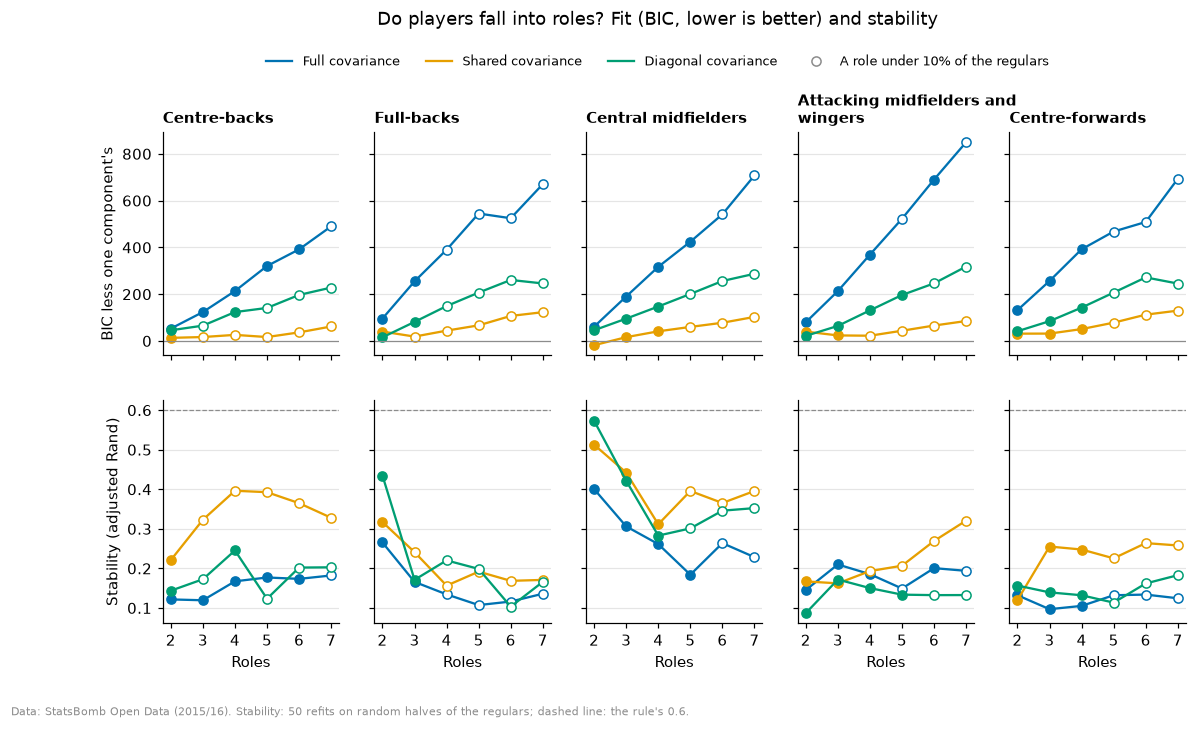

In [15]:
fig, axs = plt.subplots(2, len(OUTFIELD), figsize=(12, 5.8), sharex=True, sharey="row")
for j, g in enumerate(OUTFIELD):
    t = mixtures[mixtures.group == g]
    for i, c in enumerate(COVARIANCES):
        tc = t[t.covariance == c]
        small = (tc.smallest < MIN_SHARE).to_numpy()
        for row, col in enumerate(["against_one", "stability"]):
            ax = axs[row, j]
            ax.plot(tc.roles, tc[col], color=OKABE_ITO[i], lw=1.5, label=SHAPES[c])
            ax.plot(tc.roles[~small], tc[col][~small], "o", color=OKABE_ITO[i], ms=6)
            ax.plot(tc.roles[small], tc[col][small], "o", mfc="white", mec=OKABE_ITO[i], ms=6)
    c = rule_roles[g]
    if c is not None:
        for row, col in enumerate(["against_one", "stability"]):
            axs[row, j].plot(c.roles, c[col], "*", color="black", ms=13, zorder=5)
    axs[0, j].axhline(0, color=GREY, lw=0.8)
    axs[1, j].axhline(MIN_STABILITY, color=GREY, lw=0.8, ls="--")
    axs[0, j].set_title(GROUP_NAMES[g].replace(" and ", " and\n"), fontsize=9.5)
    axs[1, j].set_xlabel("Roles")
    axs[1, j].set_xticks(range(2, 8))
axs[0, 0].set_ylabel("BIC less one component's")
axs[1, 0].set_ylabel("Stability (adjusted Rand)")
handles = [
    *axs[0, 0].get_legend_handles_labels()[0],
    plt.Line2D([], [], ls="", marker="o", mfc="white", mec=GREY, ms=6),
]
labels = [*SHAPES.values(), "A role under 10% of the regulars"]
if any(c is not None for c in rule_roles.values()):
    handles.append(plt.Line2D([], [], ls="", marker="*", color="black", ms=11))
    labels.append("The rule's choice")
fig.legend(handles, labels, loc="upper center", ncol=len(labels), fontsize=8.5,
           bbox_to_anchor=(0.5, 1.02))  # fmt: skip
fig.suptitle("Do players fall into roles? Fit (BIC, lower is better) and stability", y=1.07)
credit(fig, "Data: StatsBomb Open Data (2015/16). Stability: 50 refits on random halves of the "
            "regulars; dashed line: the rule's 0.6.")  # fmt: skip
plt.show()

**No roles in any group.** In every group the lowest BIC is a mixture of two roles with diagonal
covariance, 16 to 46 points better than a single component, as it would be for a single cloud
that is skewed or whose descriptors correlate, which one diagonal component cannot follow. None
is reproduced by refits on half the regulars: their stability is 0.09 to 0.43, and 0.57 among
central midfielders, the closest to the rule's 0.6. No mixture of three roles or more does better
than 0.44 with every role at 10% or more: the partitions change with the players fitted, the mark
of a continuum cut in arbitrary places.

### 2.2 Style axes

If players spread out rather than group, a role is a direction, not a box: how far a centre-back
leans towards passing long or towards carrying. The axes are the principal components of each
group's standardised descriptors (regulars), varimax-rotated so that each gathers a few
descriptors and can be named. A player's score is 0 at the regulars' average and 1 at one
standard deviation. How many axes, by a rule fixed before any axis was read:

- **above chance**: start from the components whose eigenvalue stands above the 95th percentile
  of 200 shuffles of the descriptors, each shuffled on its own (parallel analysis);
- **reliable and reproducible**: drop the last axis until every axis has a split-half
  reliability of 0.7 or more at 900 minutes (values on an even share, not shrunk; 50 draws) and
  a mean Tucker congruence of 0.85 or more with the axes fitted on random halves of the regulars
  (1 is the same axis). The mean is taken over 20,000 halves, which fixes it to about ±0.001:
  over fewer it moves enough from one sample to the next to decide an axis on the line by
  chance.

In [16]:
trail, AXES, lowest = [], {}, {}
for g, x in fitted.items():
    n = above_chance = retained(parallel_analysis(x, seed=2016))
    ids = long_season.index[long_season.comparison_group == g]
    while n:
        axes = fit_axes(x, n)

        def rate_fn(s, g=g, axes=axes):
            even = adjust(descriptors(s), own_share(s), pd.Series(g, index=s.index), slopes)
            return axes.scores(even)

        curve = split_half_reliability(
            rows[rows.player_id.isin(ids)], long_season.league.loc[ids], list(axes.weights),
            [RELIABILITY_MINUTES], columns=COLUMNS, rate_fn=rate_fn,
        )  # fmt: skip
        r = curve[list(axes.weights)].mean()
        halves = congruence(x, axes, seed=2016)  # one row per half
        found = halves.mean()
        lowest[g, n] = halves[found.idxmin()]
        kept = (r >= MIN_AXIS_RELIABILITY).all() and (found >= MIN_CONGRUENCE).all()
        trail.append({
            "Group": GROUP_NAMES[g], "Above chance": above_chance, "Axes tried": n,
            "Lowest reliability": r.min(), "Lowest congruence": found.min(),
            "Kept": "yes" if kept else "no",
        })  # fmt: skip
        if kept:
            AXES[g] = (axes, r, found)
            break
        n -= 1
assert {g: AXES[g][0].weights.shape[1] if g in AXES else 0 for g in fitted} == cfg.roles.axes
display(
    pd.DataFrame(trail).style.hide(axis="index")
    .format("{:.2f}", subset=["Lowest reliability", "Lowest congruence"])
    .set_caption("How many axes: the rule, step by step")
)  # fmt: skip

Group,Above chance,Axes tried,Lowest reliability,Lowest congruence,Kept
Centre-backs,4,4,0.62,0.90,no
Centre-backs,4,3,0.74,0.86,yes
Full-backs,4,4,0.64,0.95,no
Full-backs,4,3,0.72,0.89,yes
Central midfielders,4,4,0.78,0.89,yes
Attacking midfielders and wingers,4,4,0.81,0.91,yes
Centre-forwards,5,5,0.74,0.82,no
Centre-forwards,5,4,0.74,0.85,no
Centre-forwards,5,3,0.76,0.89,yes


In [17]:
# How precise the mean is, and how far it moves over fewer halves: the lowest axis's mean over
# blocks of the same halves.
recheck = []
for (g, n), c in lowest.items():
    by = {size: c.groupby(np.arange(len(c)) // size).mean() for size in (1000, 50)}
    recheck.append(
        f"{GROUP_NAMES[g].lower()} {n} axes {c.mean():.3f} ± {c.sem():.3f} (1,000 halves "
        f"{by[1000].min():.3f} to {by[1000].max():.3f}; 50 halves {by[50].min():.2f} to "
        f"{by[50].max():.2f})"
    )
print(
    f"Lowest mean congruence over {len(c):,} halves, ± its standard error, and its range over "
    "blocks of fewer of them: " + "; ".join(recheck) + "."
)

Lowest mean congruence over 20,000 halves, ± its standard error, and its range over blocks of fewer of them: centre-backs 4 axes 0.902 ± 0.001 (1,000 halves 0.897 to 0.906; 50 halves 0.86 to 0.94); centre-backs 3 axes 0.865 ± 0.001 (1,000 halves 0.853 to 0.870; 50 halves 0.80 to 0.92); full-backs 4 axes 0.952 ± 0.000 (1,000 halves 0.951 to 0.954; 50 halves 0.93 to 0.96); full-backs 3 axes 0.888 ± 0.001 (1,000 halves 0.878 to 0.897; 50 halves 0.83 to 0.93); central midfielders 4 axes 0.892 ± 0.001 (1,000 halves 0.884 to 0.896; 50 halves 0.85 to 0.93); attacking midfielders and wingers 4 axes 0.909 ± 0.001 (1,000 halves 0.904 to 0.914; 50 halves 0.87 to 0.94); centre-forwards 5 axes 0.818 ± 0.001 (1,000 halves 0.810 to 0.828; 50 halves 0.76 to 0.87); centre-forwards 4 axes 0.845 ± 0.001 (1,000 halves 0.835 to 0.855; 50 halves 0.77 to 0.90); centre-forwards 3 axes 0.890 ± 0.001 (1,000 halves 0.884 to 0.897; 50 halves 0.84 to 0.93).


In [18]:
def ends(loading, sign, top=3):
    """The `top` descriptors at one end of an axis, with their loadings."""
    end = (sign * loading).sort_values(ascending=False).head(top)
    return ", ".join(f"{lower(LABELS[m])} {sign * v:+.2f}" for m, v in end.items())


axis_table = []
for g, (axes, r, found) in AXES.items():
    variation = (axes.loadings**2).sum() / len(axes.loadings)
    for a in axes.loadings:
        axis_table.append({
            "Group": GROUP_NAMES[g], "Axis": a, "Variation": variation[a], "Reliability": r[a],
            "Congruence": found[a], "High end": ends(axes.loadings[a], 1),
            "Low end": ends(axes.loadings[a], -1),
        })  # fmt: skip
display(
    pd.DataFrame(axis_table).style.hide(axis="index")
    .format("{:.0%}", subset="Variation").format("{:.2f}", subset=["Reliability", "Congruence"])
    .set_caption("Style axes: what each opposes (loadings: correlations with the axis)")
)  # fmt: skip
for g in fitted.keys() - AXES.keys():
    first = fit_axes(fitted[g], 1).loadings[1]
    step = next(t for t in trail if t["Group"] == GROUP_NAMES[g] and t["Axes tried"] == 1)
    print(
        f"{GROUP_NAMES[g]}: no axis kept. Their first component would set "
        f"{ends(first, 1)} against {ends(first, -1)} (reliability "
        f"{step['Lowest reliability']:.2f}, congruence {step['Lowest congruence']:.2f})."
    )

Group,Axis,Variation,Reliability,Congruence,High end,Low end
Centre-backs,1,20%,0.79,0.94,"pass length (yards) +0.84, switches per pass +0.79, distance carried per touch (yards) +0.39","backward passes per pass -0.31, pressures per engagement -0.26, touch width (from the centre line) -0.09"
Centre-backs,2,18%,0.74,0.93,"open-play passes per touch +0.78, touches in the box, per touch +0.65, forward passes per pass +0.50","distance carried per touch (yards) -0.54, touch width (from the centre line) -0.21, switches per pass -0.12"
Centre-backs,3,17%,0.77,0.86,"touch width (from the centre line) +0.82, forward passes per pass +0.61, pressures per engagement +0.55","switches per pass -0.24, pass length (yards) -0.08, touches in the box, per touch -0.07"
Full-backs,1,20%,0.80,0.93,"clearances and blocks per action +0.84, aerial duels per touch +0.62, open-play passes per touch +0.59","dribbles per touch -0.75, distance carried per touch (yards) -0.73, height of defensive actions (x) -0.53"
Full-backs,2,19%,0.77,0.91,"spread of touches along the pitch +0.77, shots per touch +0.72, touches in the box, per touch +0.71","open-play passes per touch -0.52, tackles per defensive action -0.14, clearances and blocks per action +0.02"
Full-backs,3,13%,0.72,0.89,"pass length (yards) +0.79, switches per pass +0.63, crosses per pass +0.40","pressures per engagement -0.50, backward passes per pass -0.48, tackles per defensive action -0.39"
Central midfielders,1,29%,0.89,0.99,"touch height (mean x) +0.90, spread of touches along the pitch +0.84, touch width (from the centre line) +0.82","open-play passes per touch -0.61, pass length (yards) -0.20, clearances and blocks per action -0.15"
Central midfielders,2,13%,0.82,0.96,"pass length (yards) +0.83, switches per pass +0.73, high passes per pass +0.59","pressures per engagement -0.61, tackles per defensive action -0.59, backward passes per pass -0.47"
Central midfielders,3,12%,0.78,0.96,"aerial duels per touch +0.83, clearances and blocks per action +0.78, touches in the box, per touch +0.49","pressures per engagement -0.31, switches per pass -0.31, spread of touches across the pitch -0.30"
Central midfielders,4,12%,0.83,0.89,"forward passes per pass +0.64, spread of touches across the pitch +0.56, open-play passes per touch +0.56","distance carried per touch (yards) -0.61, dribbles per touch -0.52, backward passes per pass -0.37"


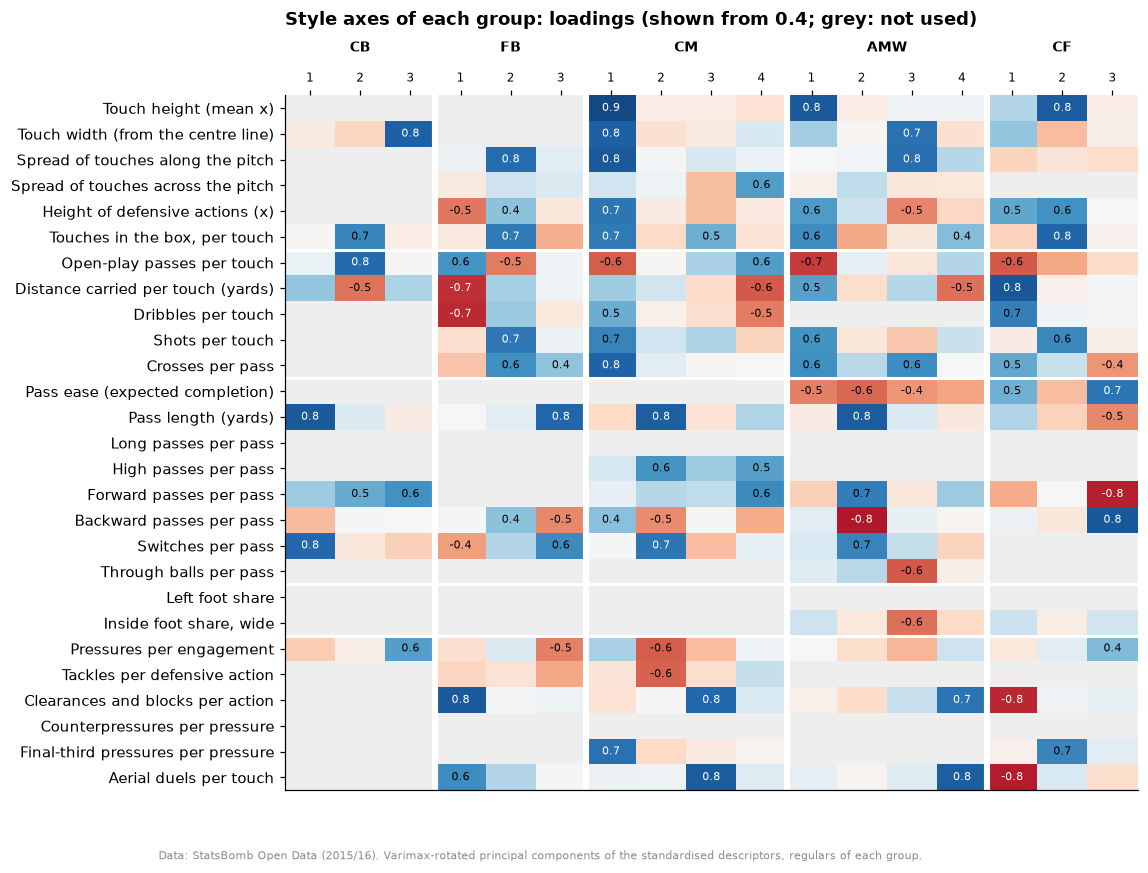

In [19]:
columns = [(g, a) for g, (axes, _, _) in AXES.items() for a in axes.loadings]
grid = pd.DataFrame(np.nan, index=NAMES, columns=pd.MultiIndex.from_tuples(columns))
for g, (axes, _, _) in AXES.items():
    for a in axes.loadings:
        grid.loc[axes.loadings.index, (g, a)] = axes.loadings[a]
fig, ax = plt.subplots(figsize=(10, 7.8))
fig.subplots_adjust(top=0.86, bottom=0.05)
cmap = plt.get_cmap("RdBu").copy()
cmap.set_bad("#EEEEEE")
ax.imshow(grid.to_numpy(), cmap=cmap, vmin=-1, vmax=1, aspect="auto")
for (i, j), v in np.ndenumerate(grid.to_numpy()):
    if abs(v) >= 0.4:
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) >= 0.7 else "black")  # fmt: skip
ax.set_xticks(range(len(columns)), [str(a) for _, a in columns], fontsize=8)
ax.xaxis.tick_top()
start = 0
for g, (axes, _, _) in AXES.items():
    n = axes.loadings.shape[1]
    ax.text(start + (n - 1) / 2, -2.2, g, ha="center", fontsize=9, fontweight="bold")
    start += n
    if start < len(columns):
        ax.axvline(start - 0.5, color="white", lw=4)
ax.set_yticks(range(len(NAMES)), [LABELS[m] for m in NAMES])
for e in np.cumsum([len(ms) for ms in FAMILIES.values()])[:-1] - 0.5:
    ax.axhline(e, color="white", lw=2)
ax.grid(False)
ax.set_title("Style axes of each group: loadings (shown from 0.4; grey: not used)", pad=46)
credit(fig, "Data: StatsBomb Open Data (2015/16). Varimax-rotated principal components of the "
            "standardised descriptors, regulars of each group.")  # fmt: skip
plt.show()

**Players differ along three or four axes per group, and the axes are reliable.**

- Parallel analysis finds four components above chance in every group but centre-forwards
  (five). The rule keeps three axes for centre-backs, full-backs and centre-forwards and four for
  central midfielders and for attacking midfielders and wingers, together 52% to 66% of the
  descriptors' variation. Their scores have a reliability of 0.72 to 0.89 at 900 minutes,
  against a median of 0.61 to 0.71 for the profiles' statistics, and the axes are found again in
  half the players (congruence 0.86 to 0.99).
- The axes left out fail one test or the other: a fourth centre-back axis and a fourth full-back
  axis are not reliable (0.62 and 0.64), centre-forwards' fifth and fourth are not found again
  (0.818 and 0.845 ± 0.001). The fourth sits on the line: a mean over 1,000 halves reads it
  anywhere from 0.835 to 0.855, over 50 halves from 0.77 to 0.90.
- Each axis gathers a few descriptors and can be named (section 3). Centre-backs, for instance,
  are set apart by how far they pass and switch play, by how often they pass and reach the box
  against how far they carry, and by how wide they stand, pass forward and press; centre-forwards
  by carrying and dribbling against heading and clearing, by playing high, in the box and
  pressing in the final third, and by laying the ball back against passing it forward.

### 2.3 The axes, the positions and the team

Among each group's regulars: how far the position StatsBomb records (the one each player played
most, positions with 10 or more regulars) places a player on each axis, beyond chance, as the
team's share is measured (`leagues.team_effect`); how well the descriptors tell those positions
apart (a cross-validated logistic regression, balanced accuracy: 0.5 is chance with two
positions, 0.33 with three); how much of each axis the team explains; how far each axis follows
the team's possession; and whether a season's deployment still shows through: the share of a
player's minutes outside their group (all their matches) and the share on their less-used
flank (Spearman).

In [20]:
KIND = {
    "Right Center Back": "Right centre-back", "Left Center Back": "Left centre-back",
    "Center Back": "Centre of a back three", "Right Back": "Full-back", "Left Back": "Full-back",
    "Right Wing Back": "Wing-back", "Left Wing Back": "Wing-back",
    "Center Defensive Midfield": "Holding, alone", "Right Defensive Midfield": "Holding, in a pair",
    "Left Defensive Midfield": "Holding, in a pair", "Right Center Midfield": "Central midfield",
    "Center Midfield": "Central midfield", "Left Center Midfield": "Central midfield",
    "Right Wing": "Winger", "Left Wing": "Winger", "Right Midfield": "Wide midfielder",
    "Left Midfield": "Wide midfielder", "Right Attacking Midfield": "Attacking midfielder",
    "Center Attacking Midfield": "Attacking midfielder",
    "Left Attacking Midfield": "Attacking midfielder", "Center Forward": "Lone forward",
    "Right Center Forward": "Forward in a pair", "Left Center Forward": "Forward in a pair",
}  # StatsBomb's positions, by the kind of slot  # fmt: skip
main_kind = (
    positions.assign(kind=positions.position.map(KIND))
    .groupby(["player_id", "kind"]).minutes.sum().unstack(fill_value=0).idxmax(axis=1)
)  # fmt: skip


def common_kinds(ids):
    """The position each player played most, positions with 10 or more of `ids`."""
    kinds = main_kind.reindex(ids)
    return kinds[kinds.map(kinds.value_counts()) >= 10]


telling = []
for g, x in fitted.items():
    kinds = common_kinds(x.index)
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000,
                                                             class_weight="balanced"))  # fmt: skip
    folds = StratifiedKFold(5, shuffle=True, random_state=2016)
    accuracy = cross_val_score(clf, x.loc[kinds.index], kinds, cv=folds,
                               scoring="balanced_accuracy").mean()  # fmt: skip
    telling.append(
        f"{GROUP_NAMES[g].lower()} {accuracy:.2f} ("
        + ", ".join(f"{k.lower()} {n}" for k, n in kinds.value_counts().items())
        + ")"
    )
print("Positions told apart by the descriptors (balanced accuracy): " + "; ".join(telling) + ".")

both_flanks = by_flank.min(axis=1) / on_flank.replace(0, np.nan)
scores, checks = {}, []
for g, (axes, _, _) in AXES.items():
    scores[g] = axes.scores(shrunk.loc[group.index[group == g], DESCRIPTORS[g]])
    ids = fitted[g].index
    kinds = common_kinds(ids)
    s = scores[g].loc[ids]
    for a in s:
        by_kind = s.loc[kinds.index, a].groupby(kinds).mean().sort_values()
        checks.append({
            "Group": GROUP_NAMES[g], "Axis": a,
            "Mean score by position": ", ".join(f"{k} {v:+.2f}" for k, v in by_kind.items()),
            "Position": team_effect(pd.DataFrame({"v": s.loc[kinds.index, a], "team": kinds,
                                                  "group": g}), "v"),
            "Team": team_effect(pd.DataFrame({"v": s[a], "team": main_team.loc[ids], "group": g}),
                                "v"),
            "Possession": s[a].corr(share.loc[ids], method="spearman"),
            "Outside the group": s[a].corr(outside_group.loc[ids], method="spearman"),
            "Both flanks": s[a].corr(both_flanks.loc[ids], method="spearman"),
        })  # fmt: skip
display(
    pd.DataFrame(checks).style.hide(axis="index")
    .format("{:+.2f}", subset=["Position", "Team", "Possession", "Outside the group",
                               "Both flanks"])
    .set_caption("The axes against the recorded positions (share beyond chance), the team (share "
                 "beyond chance), possession and deployment (Spearman), regulars")
)  # fmt: skip

Positions told apart by the descriptors (balanced accuracy): centre-backs 0.57 (right centre-back 130, left centre-back 112); full-backs 0.75 (full-back 221, wing-back 19); central midfielders 0.64 (holding, in a pair 134, central midfield 107, holding, alone 43); attacking midfielders and wingers 0.67 (winger 160, wide midfielder 52, attacking midfielder 41); centre-forwards 0.57 (lone forward 84, forward in a pair 65).


Group,Axis,Mean score by position,Position,Team,Possession,Outside the group,Both flanks
Centre-backs,1,"Right centre-back -0.09, Left centre-back +0.07",+0.00,+0.13,-0.32,-0.10,-0.07
Centre-backs,2,"Left centre-back -0.05, Right centre-back +0.05",-0.00,+0.42,-0.33,-0.23,+0.01
Centre-backs,3,"Left centre-back +0.05, Right centre-back +0.08",-0.00,+0.02,-0.16,+0.23,-0.15
Full-backs,1,"Wing-back -0.77, Full-back +0.07",+0.05,+0.21,-0.10,+0.01,-0.08
Full-backs,2,"Full-back -0.13, Wing-back +1.46",+0.18,+0.48,-0.14,+0.11,-0.02
Full-backs,3,"Wing-back -0.37, Full-back +0.03",+0.01,+0.23,-0.34,+0.03,-0.11
Central midfielders,1,"Holding, alone -0.90, Holding, in a pair -0.34, Central midfield +0.79",+0.41,+0.02,-0.16,+0.30,-0.26
Central midfielders,2,"Central midfield -0.27, Holding, in a pair +0.06, Holding, alone +0.49",+0.06,+0.14,-0.29,-0.08,+0.13
Central midfielders,3,"Central midfield -0.04, Holding, in a pair -0.00, Holding, alone +0.10",-0.00,-0.05,-0.20,+0.04,-0.07
Central midfielders,4,"Central midfield -0.25, Holding, alone +0.11, Holding, in a pair +0.16",+0.03,+0.22,-0.27,-0.02,+0.15


The same descriptors, axes and scores are built by `make profiles` (`roles.build_style`, the
`style_*` tables), which later notebooks read. They match the ones fitted here:

In [21]:
built = con.sql("SELECT player_id, comparison_group, axis, score FROM style_scores").df()
here = pd.concat(
    s.rename_axis(index="player_id", columns="axis").stack().rename("here").reset_index()
    .assign(comparison_group=g)
    for g, s in scores.items()
)  # fmt: skip
both = built.merge(here, on=["player_id", "comparison_group", "axis"], validate="1:1")
built_values = con.sql("SELECT player_id, descriptor, shrunk FROM style_values").df()
shrunk_here = shrunk.to_numpy()[
    shrunk.index.get_indexer(built_values.player_id),
    shrunk.columns.get_indexer(built_values.descriptor),
]
gaps = (both.score - both.here).abs().max(), np.abs(built_values.shrunk - shrunk_here).max()
assert len(both) == len(built) == len(here) and max(gaps) < 1e-9
print(
    f"style_scores: {len(built):,} scores, largest difference {gaps[0]:.0e}; style_values: "
    f"{len(built_values):,} shrunk descriptors, largest difference {gaps[1]:.0e}."
)

style_scores: 4,631 scores, largest difference 0e+00; style_values: 22,861 shrunk descriptors, largest difference 0e+00.


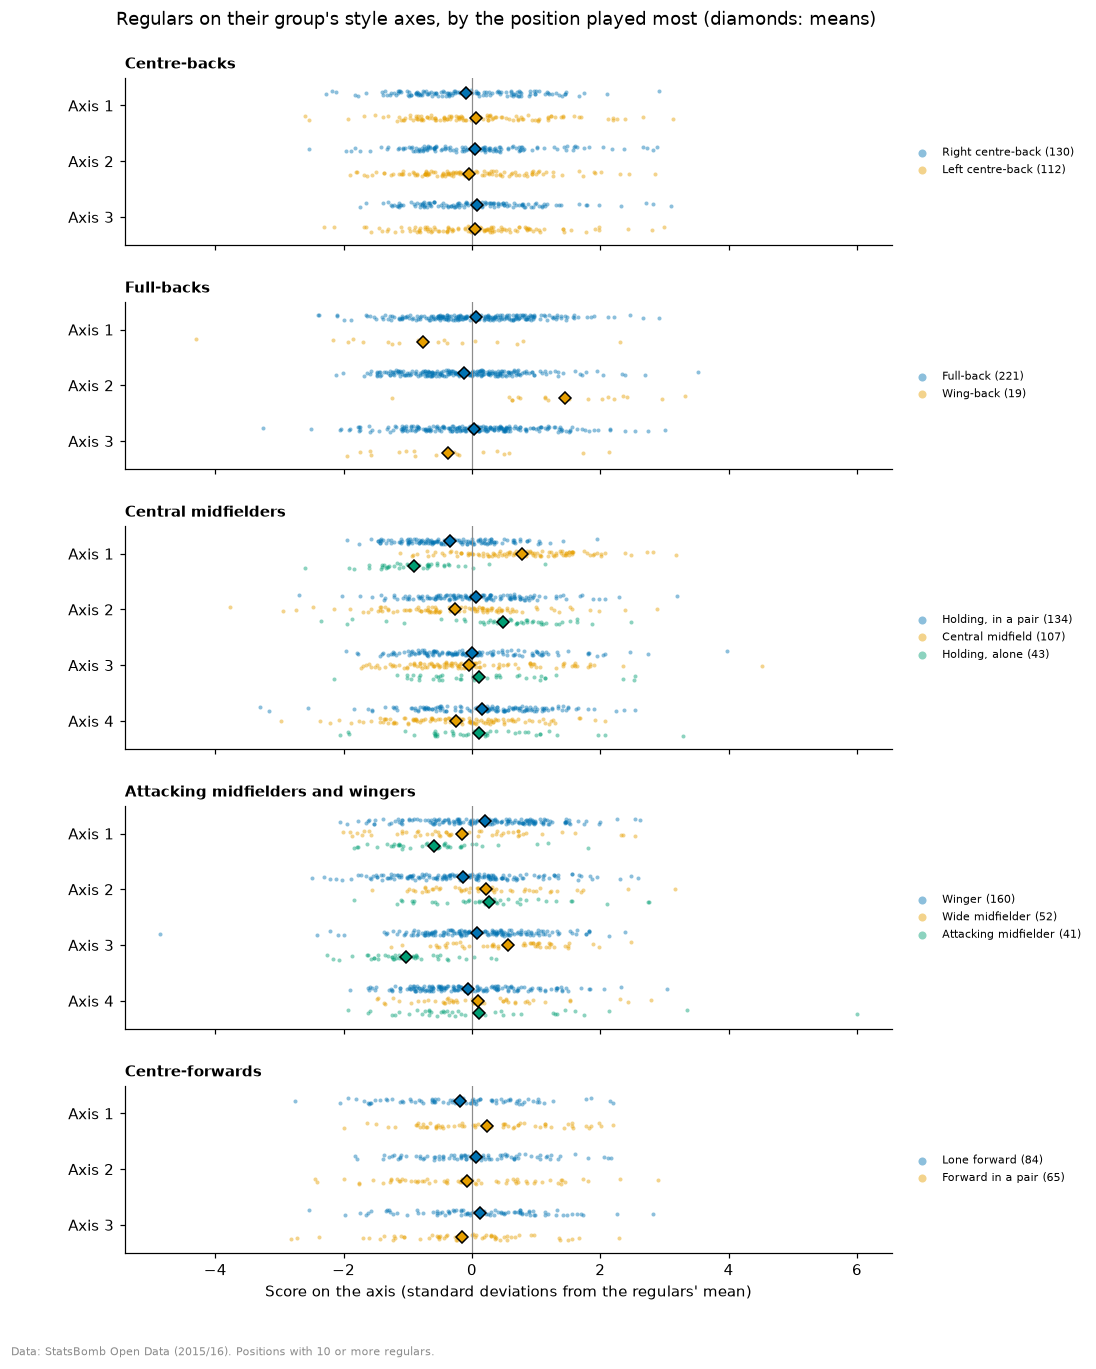

In [22]:
rows_per_group = [AXES[g][0].weights.shape[1] for g in AXES]
fig, axs = plt.subplots(len(AXES), 1, figsize=(9, 1.6 + 0.62 * sum(rows_per_group)), sharex=True,
                        gridspec_kw={"height_ratios": rows_per_group})  # fmt: skip
fig.subplots_adjust(top=0.93, bottom=0.05, hspace=0.3)
rng = np.random.default_rng(2016)
for ax, g in zip(axs, AXES, strict=True):
    s = scores[g].loc[fitted[g].index]
    kinds = common_kinds(s.index)
    order = kinds.value_counts().index
    offsets = np.linspace(-0.22, 0.22, len(order))
    for i, k in enumerate(order):
        on = kinds.index[kinds == k]
        for row, a in enumerate(s):
            y = row + offsets[i] + rng.uniform(-0.05, 0.05, len(on))
            ax.scatter(s.loc[on, a], y, s=7, color=OKABE_ITO[i], alpha=0.45, lw=0,
                       label=f"{k} ({len(on)})" if row == 0 else None)  # fmt: skip
            ax.plot(s.loc[on, a].mean(), row + offsets[i], "D", color=OKABE_ITO[i], mec="black",
                    ms=6, zorder=5)  # fmt: skip
    ax.set_yticks(range(s.shape[1]), [f"Axis {a}" for a in s])
    ax.set_ylim(s.shape[1] - 0.5, -0.5)
    ax.axvline(0, color=GREY, lw=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_title(GROUP_NAMES[g], fontsize=9.5, loc="left")
    ax.legend(fontsize=7.5, loc="center left", bbox_to_anchor=(1.01, 0.5), markerscale=2,
              frameon=False)  # fmt: skip
axs[-1].set_xlabel("Score on the axis (standard deviations from the regulars' mean)")
fig.suptitle("Regulars on their group's style axes, by the position played most (diamonds: means)")
credit(fig, "Data: StatsBomb Open Data (2015/16). Positions with 10 or more regulars.")
plt.show()

**Positions explain little of a style; the team explains up to half of an axis.**

- The descriptors tell the recorded positions apart better than chance but far from surely: a
  balanced accuracy of 0.64 and 0.67 for central midfielders' and for attacking midfielders' and
  wingers' three kinds of position (chance 0.33), 0.57 for a lone centre-forward against a pair
  and 0.75 for wing-backs against full-backs (chance 0.50). Centre-backs' sides are barely told
  apart (0.57): without the inside foot their descriptors no longer say which side they play.
- A position places players clearly on three axes: holding midfielders who play alone at −0.90
  on central midfielders' first axis and central midfielders at +0.79 (the position explains
  0.41 of it), attacking midfielders at −1.03 on the attacking midfielders' and wingers' third
  (0.23), wing-backs at +1.46 on full-backs' second (0.18). Elsewhere at most 0.08.
- The team explains up to 0.48 of an axis: full-backs who attack the box (0.48, the wing-backs of
  teams that play three at the back) and centre-backs who pass often and reach the box rather
  than carry (0.42). The rest are at most 0.23.
- The axes of long passing still lean against possession (−0.28 to −0.34 among centre-backs,
  full-backs, central midfielders, attacking midfielders and wingers): each descriptor was put
  on an even share within players, but between teams those with less of the ball play longer, as
  section 1.3 found for high passes.
- A season's deployment no longer shows through: no axis follows the share of a player's minutes
  outside their group or on their less-used flank beyond 0.35 (Spearman). The largest:
  centre-forwards who also played outside their group stand lower on the second axis (−0.35,
  playing high and in the box), central midfielders who did stand higher on the first (+0.30,
  playing high and wide).

### What section 2 shows

- **There are no discrete roles in this data.** Gaussian mixtures find no group of players that
  half the regulars reproduce, in any comparison group. Within a comparison group, style is a
  continuum.
- **Style is measured on three or four axes per group**, varimax-rotated principal components of
  the descriptors: reliable at 0.72 to 0.89 at 900 minutes, found again in half the players
  (congruence 0.86 to 0.99), 52% to 66% of the descriptors' variation. A player's role is where
  they stand on them.
- **The positions StatsBomb records say little about style**: they place players clearly on
  only three axes, and the descriptors tell them apart well short of certainty.
- **The team explains up to half of an axis** (full-backs who attack the box, 0.48), most axes
  under a quarter; the axes of long passing lean against the team's possession; a season's
  deployment no longer shows through.

## 3. Names and portraits

Each axis is named by its two ends, from its loadings (section 2.2; the names are `roles.names`
in the config), and each name is checked against three portraits of the ends:

- **the players**: the three lowest and the three highest scores among players with 1,800 minutes
  or more in their group's positions, whose scores owe least to the shrinkage;
- **the numbers**: the medians of the descriptors that load most on the axis, as recorded (before
  the possession adjustment, in yards and shares), in the bottom and top deciles of the regulars;
- **the pitch**: where those deciles touch the ball (`style.touch_map`: each player's touches as
  shares of 5-yard zones, each player counting once, every match mirrored so that the player's
  side is the same, since a side is not a style; touches as in the descriptors, set pieces
  included), and how far apart the two ends are: the share of touches that would have to move to
  turn one end's map into the other's (total variation over 10-yard zones), against two groups
  of a tenth of the regulars drawn at random.

In [23]:
NAMED_BY = {  # (group, axis): the descriptor loading most on the axis, which its name follows
    ("CB", 1): "pass_length", ("CB", 2): "pass_share", ("CB", 3): "touch_width",
    ("FB", 1): "clearance_share", ("FB", 2): "spread_length", ("FB", 3): "pass_length",
    ("CM", 1): "touch_height", ("CM", 2): "pass_length", ("CM", 3): "aerial_share",
    ("CM", 4): "forward_share", ("AMW", 1): "touch_height", ("AMW", 2): "pass_length",
    ("AMW", 3): "spread_length", ("AMW", 4): "aerial_share", ("CF", 1): "carry_distance",
    ("CF", 2): "touch_height", ("CF", 3): "backward_share",
}  # fmt: skip
AXIS_NAMES = {  # the low end, the high end (`roles.names` in the config) and that descriptor
    (g, a): (*cfg.roles.names[g][a - 1], key) for (g, a), key in NAMED_BY.items()
}
assert set(AXIS_NAMES) == {(g, a) for g, (axes, _, _) in AXES.items() for a in axes.loadings}
for (g, a), (_, _, key) in AXIS_NAMES.items():  # the names follow the axes as fitted
    assert AXES[g][0].loadings[a].idxmax() == key, (g, a)
EXAMPLE_MINUTES = 1800
ZONE = 5  # yards


def ends(g, a):
    """The bottom and top deciles of a group's regulars on an axis."""
    s = scores[g].loc[fitted[g].index, a]
    return s.index[s <= s.quantile(0.1)], s.index[s >= s.quantile(0.9)]


maps = touch_map(con, rows[rows.player_id.isin(regulars)], zone=ZONE)


def mean_map(ids, zone=ZONE):
    """The players' mean map (each player counting once), in zones of `zone` yards."""
    m = maps.loc[ids].mean().to_numpy().reshape(80 // ZONE, 120 // ZONE)
    k = zone // ZONE
    return m.reshape(m.shape[0] // k, k, m.shape[1] // k, k).sum(axis=(1, 3))


def moved(a, b):
    """The share of touches that would have to move to turn one mean map into the other."""
    return 0.5 * np.abs(mean_map(a, 10) - mean_map(b, 10)).sum()


rng = np.random.default_rng(2016)
apart, chance = {}, {}
for g, (axes, _, _) in AXES.items():
    ids = fitted[g].index
    size = round(0.1 * len(ids))
    draws = [rng.permutation(ids)[: 2 * size] for _ in range(500)]
    chance[g] = np.array([moved(d[:size], d[size:]) for d in draws])
    for a in axes.loadings:
        apart[g, a] = moved(*ends(g, a))

named = []
for (g, a), (low, high, _) in AXIS_NAMES.items():
    s = scores[g].loc[minutes.loc[scores[g].index] >= EXAMPLE_MINUTES, a].sort_values()
    named.append({
        "Group": GROUP_NAMES[g], "Axis": a, "Low end": low, "High end": high,
        "Lowest scores": ", ".join(pool.known_as.loc[s.index[:3]]),
        "Highest scores": ", ".join(pool.known_as.loc[s.index[::-1][:3]]),
        "Touches elsewhere": apart[g, a],
    })  # fmt: skip
display(
    pd.DataFrame(named).style.hide(axis="index").format("{:.1%}", subset="Touches elsewhere")
    .set_caption(f"The style axes by their two ends, with the players at either end "
                 f"({EXAMPLE_MINUTES:,} minutes or more) and how far apart the ends' touches are")
)  # fmt: skip
by_chance = [(g, a) for (g, a), d in apart.items() if d <= np.percentile(chance[g], 95)]
print(
    "Touches elsewhere between two groups of a tenth of the regulars drawn at random, mean (95th "
    "percentile of 500 draws): "
    + "; ".join(
        f"{GROUP_NAMES[g].lower()} {c.mean():.1%} ({np.percentile(c, 95):.1%})"
        for g, c in chance.items()
    )
    + ". Axes whose ends are no further apart than the 95th percentile: "
    + ", ".join(
        f"{GROUP_NAMES[g].lower()} {a} ({' ↔ '.join(AXIS_NAMES[g, a][:2]).lower()})"
        for g, a in by_chance
    )
    + "."
)

Group,Axis,Low end,High end,Lowest scores,Highest scores,Touches elsewhere
Centre-backs,1,Short passer,Long passer,"Robert Huth, John Terry, Eliaquim Mangala","Juan Cala, Hilton, Leonardo Blanchard",6.9%
Centre-backs,2,Ball-carrier,Direct passer,"John Stones, Javier Mascherano, Nicolas N'Koulou","Scott Dann, Robert Huth, Raúl Albentosa",11.3%
Centre-backs,3,Central,Wide,"Kamil Glik, Nicolás Burdisso, Gonzalo Rodríguez","Daley Blind, Sebastian De Maio, Riccardo Gagliolo",28.8%
Full-backs,1,Dribbler,Box defender,"Bruno Peres, Gaetano Letizia, Filipe Luis","Craig Dawson, Paul Dummett, Danny Simpson",8.9%
Full-backs,2,Holds position,Gets into the box,"Ignazio Abate, Lamine Gassama, Mário Rui","Craig Dawson, Silvan Widmer, Marcos Alonso",15.6%
Full-backs,3,Short passer and presser,Long passer,"Adam Smith, Héctor Bellerín, Patrice Evra","Eros Pisano, Martin Olsson, Šime Vrsaljko",9.0%
Central midfielders,1,Deep pivot,Advanced midfielder,"Nampalys Mendy, Jérémy Clément, Thiago Motta","Marco Benassi, Daniele Baselli, Jasmin Kurtič",35.1%
Central midfielders,2,Short passer and presser,Long passer,"Vincent Koziello, Blaise Matuidi, Gelson Fernandes","Jessy Pi, Afriyie Acquah, Riccardo Montolivo",6.9%
Central midfielders,3,Ground passer,Aerial presence,"Toni Kroos, Beñat Etxebarria, Roberto Trashorras","Cheikh N'Doye, Mustapha Diallo, Marco Parolo",10.3%
Central midfielders,4,Ball-carrier,Forward passer,"Seko Fofana, Afriyie Acquah, Roque Mesa","Ignacio Camacho, David Ducourtioux, Nicolas Seube",12.2%


Touches elsewhere between two groups of a tenth of the regulars drawn at random, mean (95th percentile of 500 draws): centre-backs 4.7% (6.6%); full-backs 3.7% (5.2%); central midfielders 4.7% (7.1%); attacking midfielders and wingers 5.7% (9.0%); centre-forwards 6.4% (8.2%). Axes whose ends are no further apart than the 95th percentile: central midfielders 2 (short passer and presser ↔ long passer), attacking midfielders and wingers 4 (ball-carrier ↔ aerial presence), centre-forwards 3 (forward passer ↔ lay-off forward).


In [24]:
def natural(m, v):
    """A descriptor in its own unit: yards or a share."""
    return f"{v:.1f}" if m in YARDS else f"{v:.1%}"


typical = []
for (g, a), (low, high, _) in AXIS_NAMES.items():
    loading = AXES[g][0].loadings[a]
    strongest = loading.abs().sort_values(ascending=False).head(3)
    bottom, top = ends(g, a)
    for m in strongest.index[strongest >= 0.4]:
        typical.append({
            "Group": GROUP_NAMES[g], "Axis": f"{a}. {low} ↔ {high}", "Descriptor": LABELS[m],
            "Loading": loading[m], "Low end": natural(m, recorded.loc[bottom, m].median()),
            "Regulars": natural(m, recorded.loc[fitted[g].index, m].median()),
            "High end": natural(m, recorded.loc[top, m].median()),
        })  # fmt: skip
display(
    pd.DataFrame(typical).set_index(["Group", "Axis", "Descriptor"]).rename_axis(index=[None] * 3)
    .style.format("{:+.2f}", subset="Loading")
    .set_caption("The descriptors loading most on each axis (up to three), as recorded: medians of "
                 "the bottom decile, all regulars and the top decile")
)  # fmt: skip

In [25]:
# What three names rest on beyond the loadings: set pieces and headers.
played = rows.loc[rows.player_id.isin(regulars), ["match_id", "player_id"]]
box = (
    con.execute(f"""
    SELECT player_id, count(*) AS touches,
           count(*) FILTER (WHERE play_pattern IN ('From Corner', 'From Free Kick')) AS set_piece
    FROM events JOIN played USING (match_id, player_id)
    WHERE {TOUCH} AND {in_box("x", "y")} GROUP BY ALL
""")
    .df()
    .set_index("player_id")
)
passes = (
    con.execute(f"""
    SELECT player_id, count(*) FILTER (WHERE pass_type IN ('Corner', 'Free Kick')) AS set_pieces,
           count(*) FILTER (WHERE {OPEN_PLAY} AND end_x - x > abs(end_y - y)) AS forward,
           count(*) FILTER (WHERE {OPEN_PLAY} AND end_x - x > abs(end_y - y)
                            AND body_part = 'Head') AS headed
    FROM passes JOIN played USING (match_id, player_id) GROUP BY ALL
""")
    .df()
    .set_index("player_id")
    .reindex(regulars, fill_value=0)
)
in_box_touches = box.groupby(group.loc[box.index]).sum().loc[OUTFIELD]


def taken(ids):
    return 100 * passes.loc[ids, "set_pieces"].sum() / season.touches.loc[ids].sum()


def headed(ids):
    return passes.loc[ids, "headed"].sum() / passes.loc[ids, "forward"].sum()


cm_low, cm_high = map(taken, ends("CM", 3))
amw_low, amw_high = map(taken, ends("AMW", 2))
cf_low, cf_high = map(headed, ends("CF", 3))
print(
    "Touches in the opposition box after a corner or a free kick (regulars): "
    + ", ".join(
        f"{GROUP_NAMES[g].lower()} {r:.0%}"
        for g, r in (in_box_touches.set_piece / in_box_touches.touches).items()
    )
    + ". Corners and free kicks taken per 100 touches, low end and high end: central "
    f"midfielders' third axis {cm_low:.2f} and {cm_high:.2f}, attacking midfielders' and "
    f"wingers' second {amw_low:.2f} and {amw_high:.2f}. Headed, of centre-forwards' forward "
    f"passes in open play on their third axis: low end {cf_low:.0%}, high end {cf_high:.0%}."
)

Touches in the opposition box after a corner or a free kick (regulars): centre-backs 94%, full-backs 29%, central midfielders 39%, attacking midfielders and wingers 24%, centre-forwards 27%. Corners and free kicks taken per 100 touches, low end and high end: central midfielders' third axis 2.26 and 0.56, attacking midfielders' and wingers' second 0.50 and 2.89. Headed, of centre-forwards' forward passes in open play on their third axis: low end 14%, high end 9%.


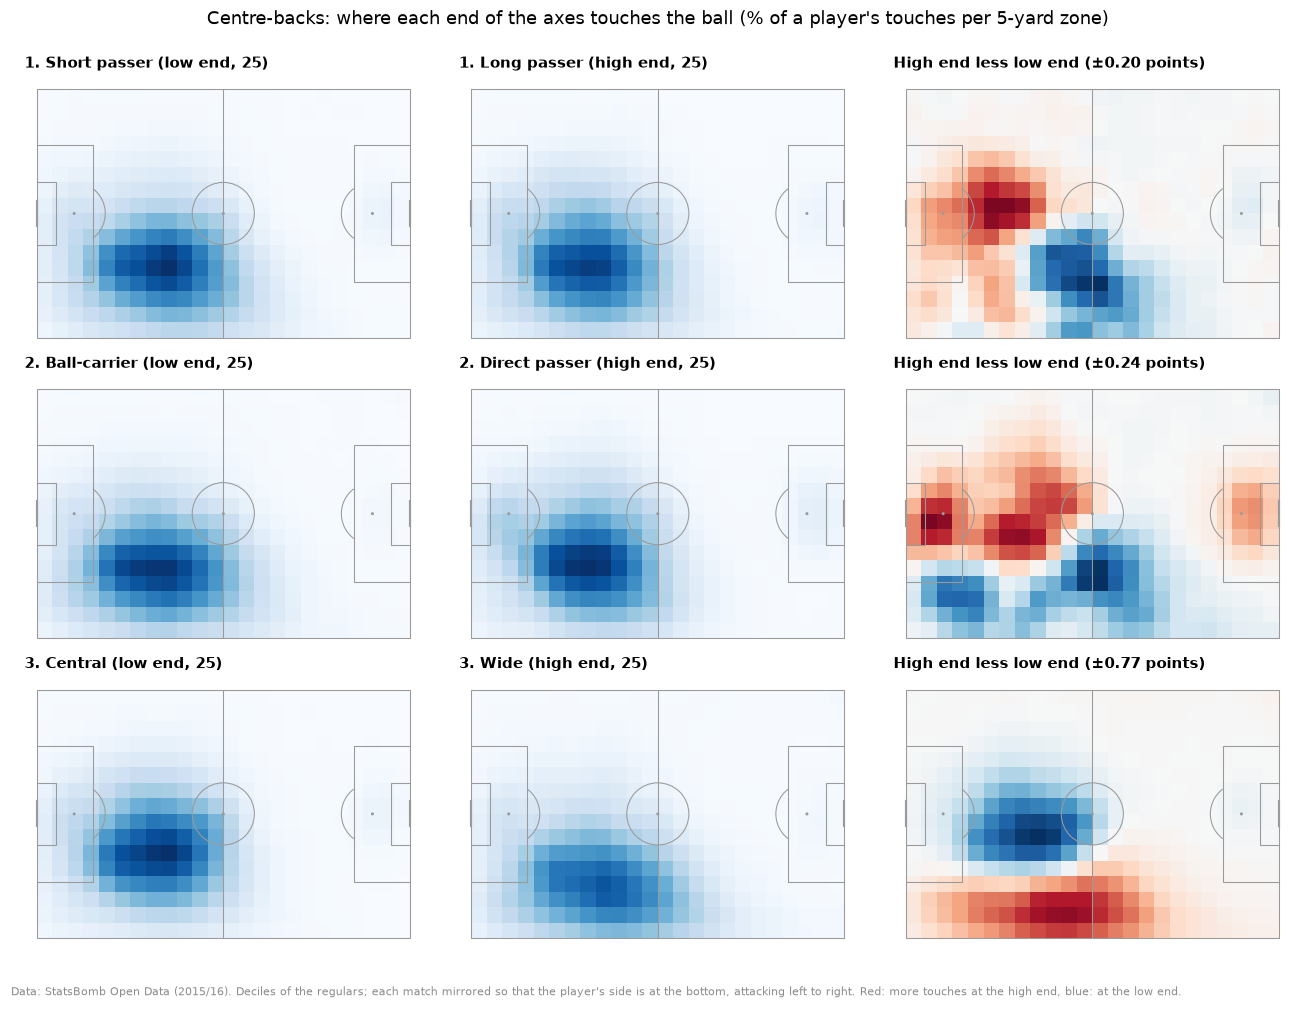

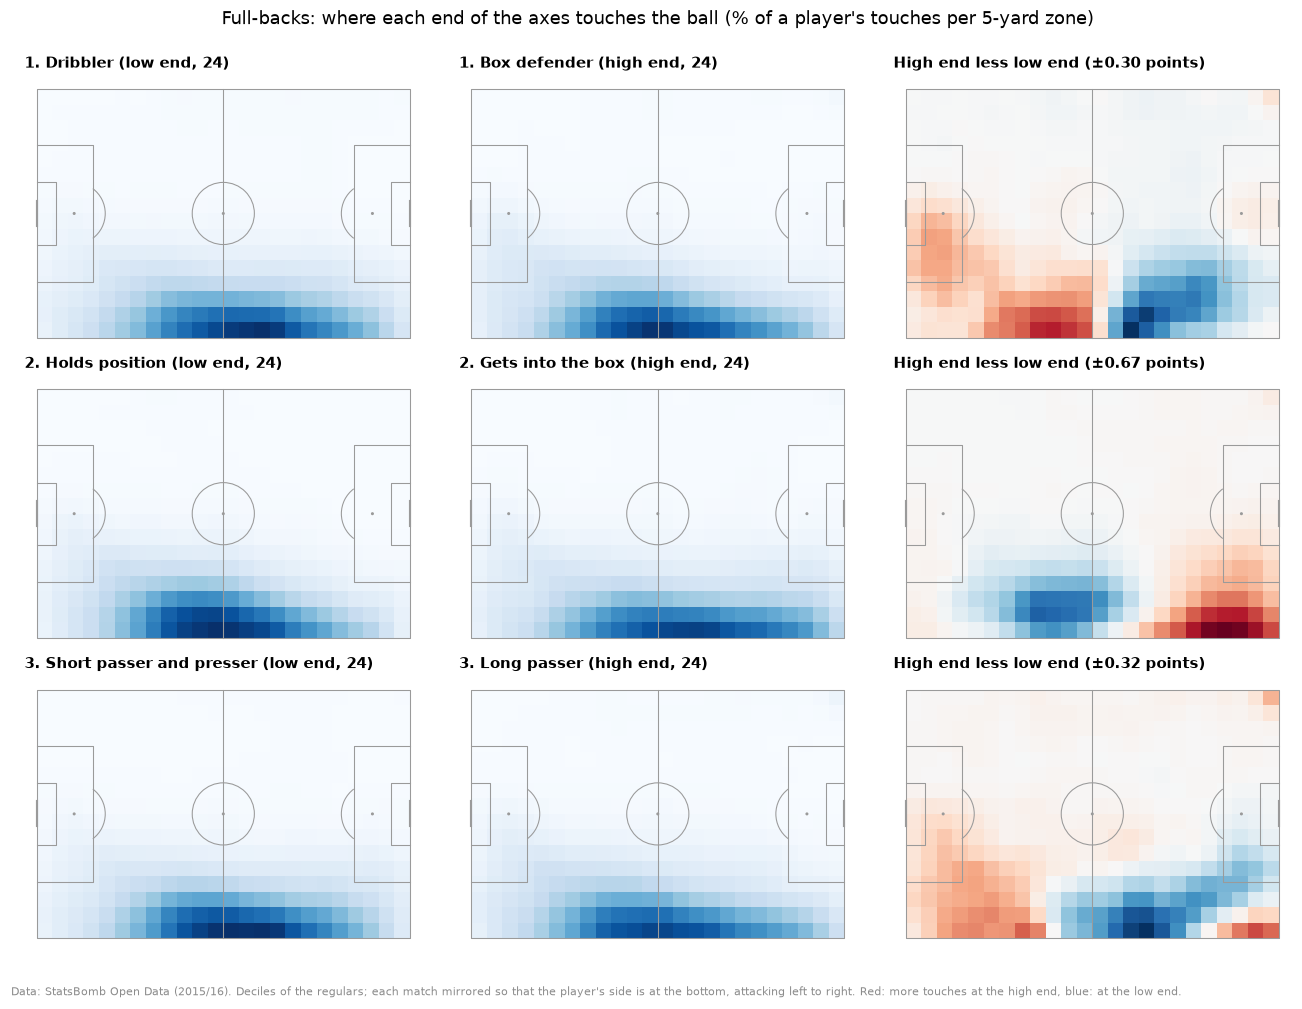

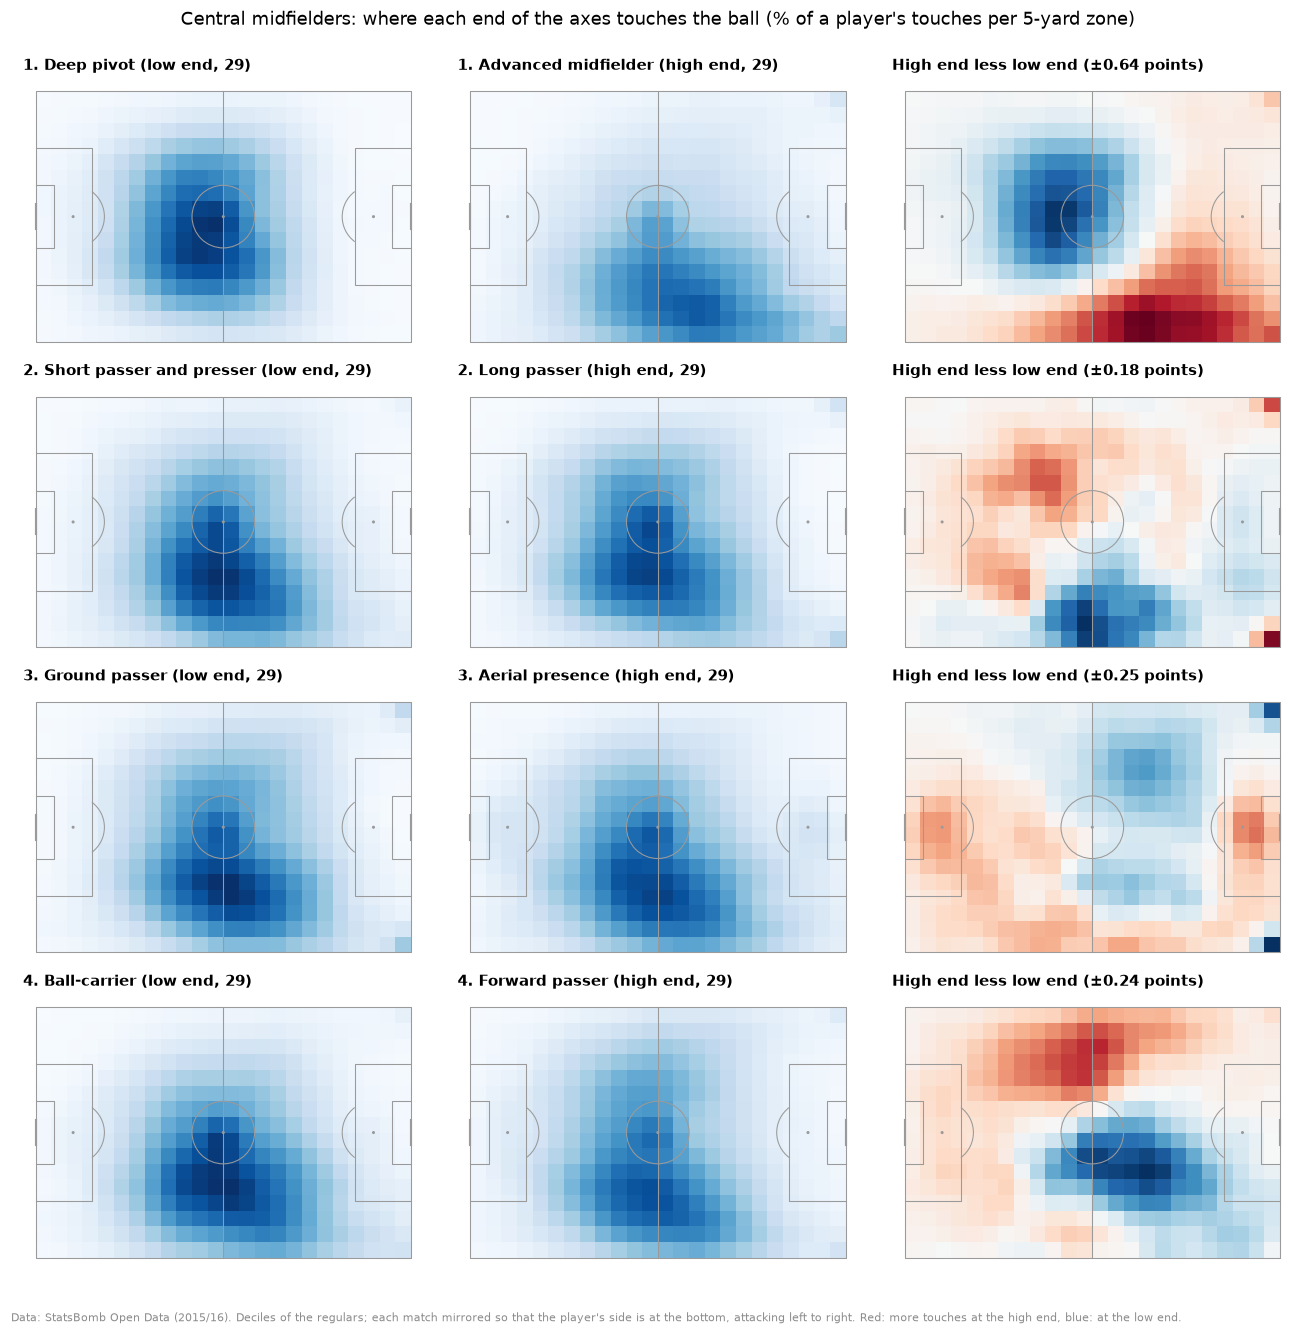

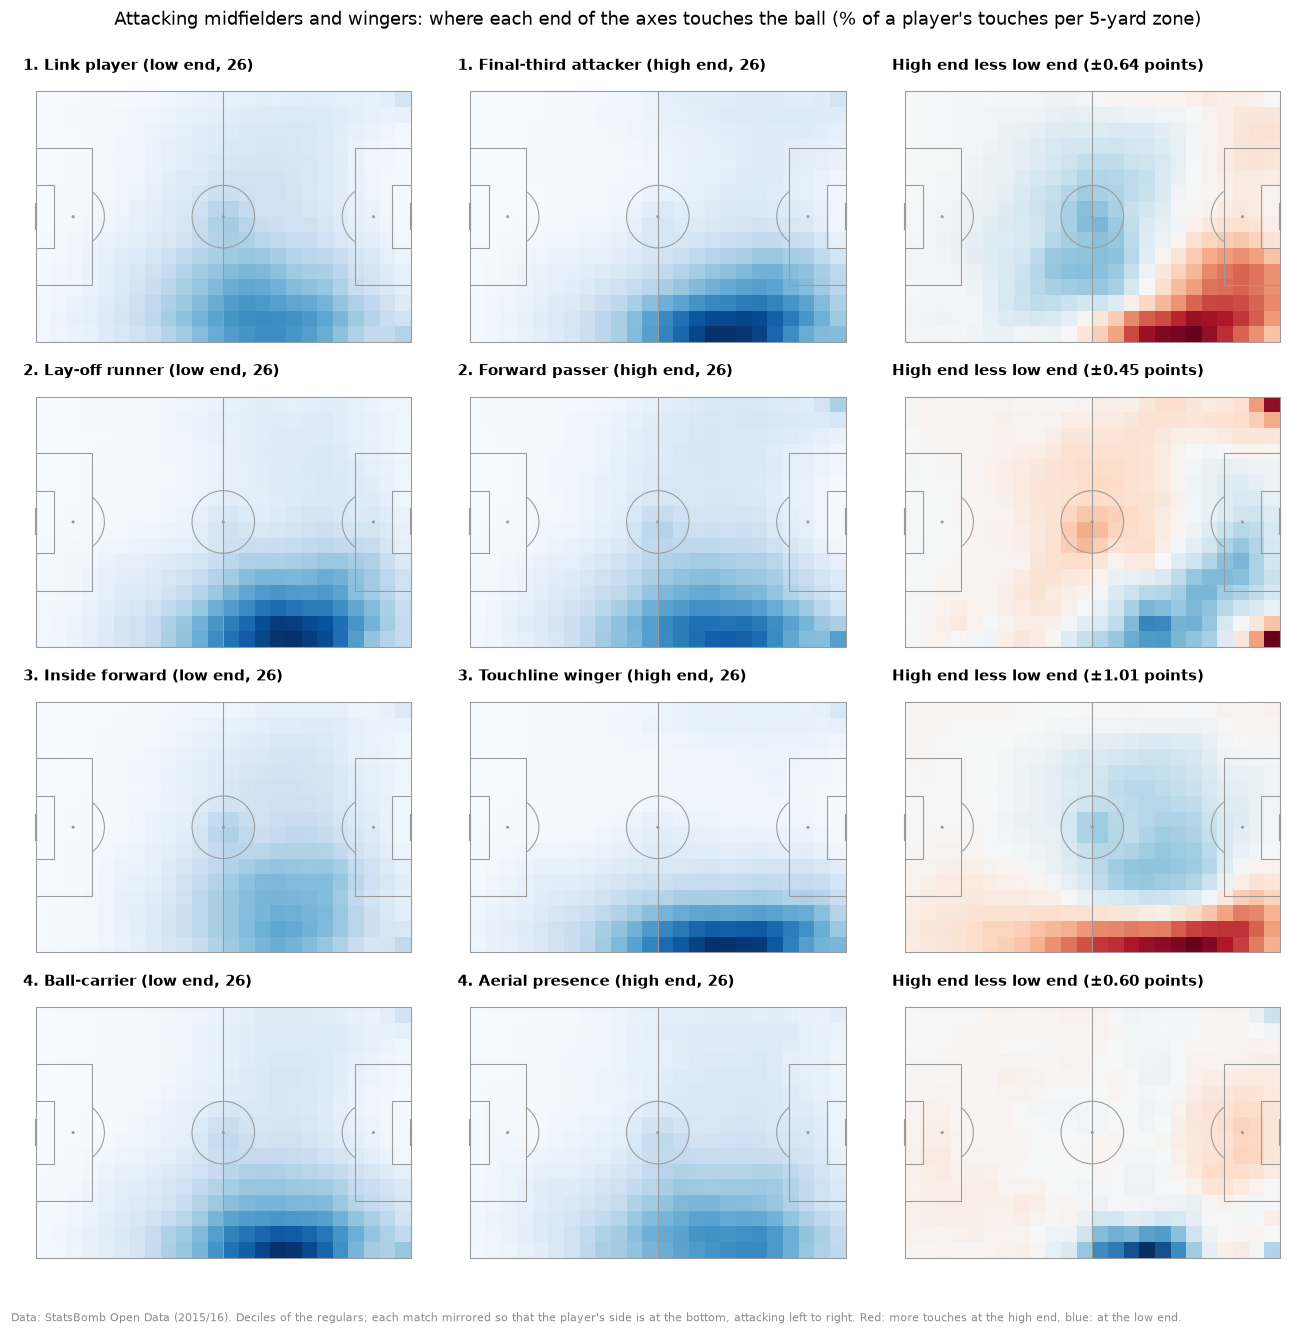

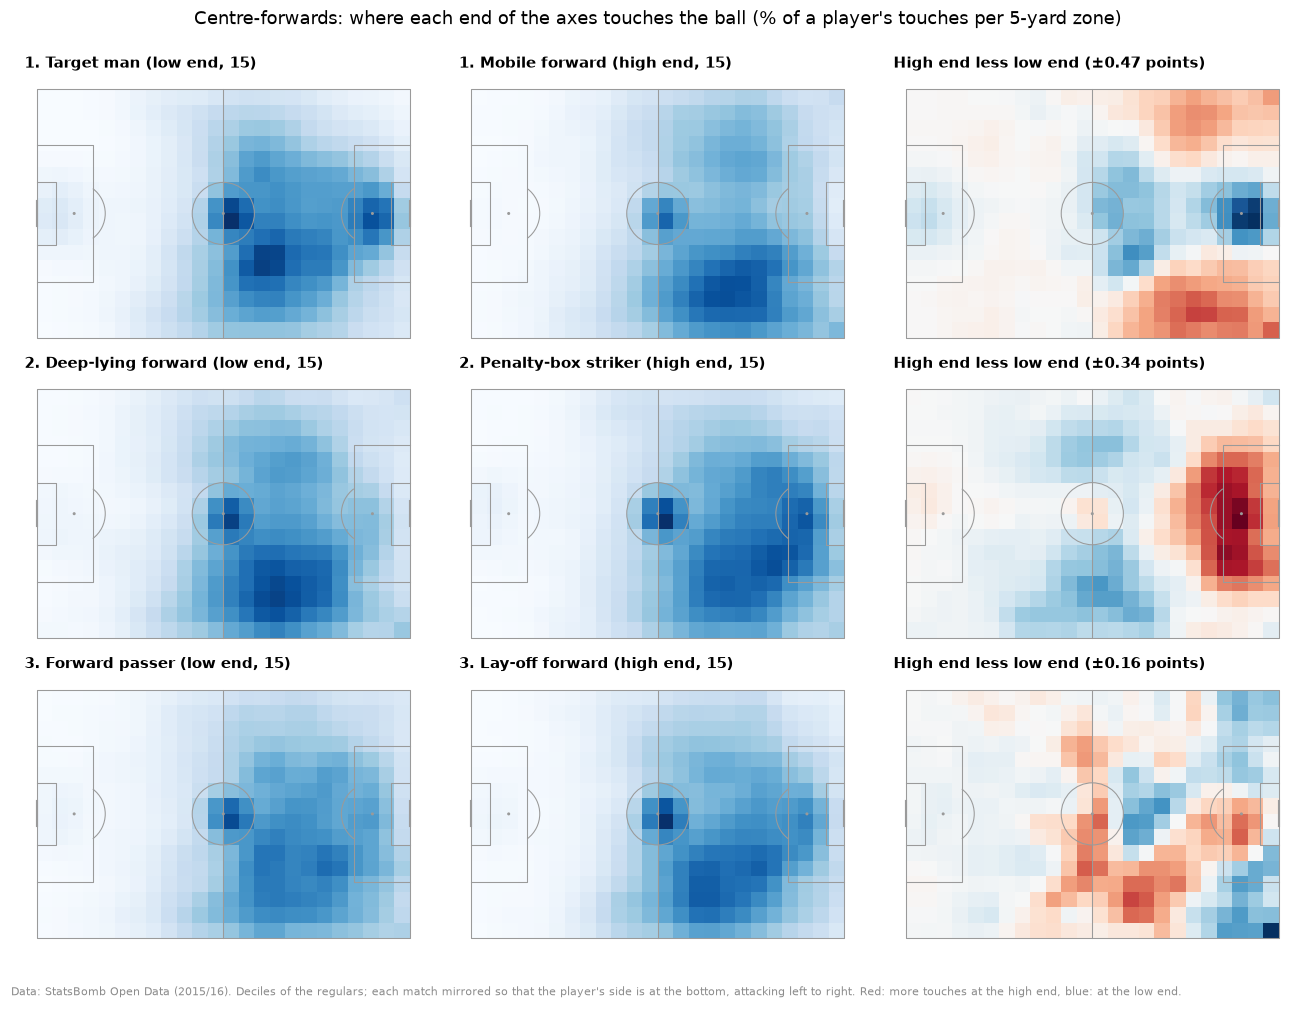

In [26]:
pitch = Pitch(pitch_type="statsbomb", line_color="#9A9A9A", linewidth=0.7, line_zorder=2)
stat = pitch.bin_statistic(np.array([60.0]), np.array([40.0]), bins=(120 // ZONE, 80 // ZONE))
for g, (axes, _, _) in AXES.items():
    n = axes.loadings.shape[1]
    fig, axs = plt.subplots(n, 3, figsize=(12, 2.9 * n))
    for row, a in enumerate(axes.loadings):
        low, high, _ = AXIS_NAMES[g, a]
        bottom, top = ends(g, a)
        low_map, high_map = (
            gaussian_filter(mean_map(ids), 0.8, mode="nearest") * 100 for ids in (bottom, top)
        )
        most, gap = max(low_map.max(), high_map.max()), np.abs(high_map - low_map).max()
        panels = [
            (f"{a}. {low} (low end, {len(bottom)})", low_map, "Blues", 0, most),
            (f"{a}. {high} (high end, {len(top)})", high_map, "Blues", 0, most),
            (f"High end less low end (±{gap:.2f} points)", high_map - low_map, "RdBu_r", -gap, gap),
        ]
        for ax, (title, values, cmap, vmin, vmax) in zip(axs[row], panels, strict=True):
            pitch.draw(ax=ax)
            stat["statistic"] = values
            pitch.heatmap(stat, ax=ax, cmap=cmap, vmin=vmin, vmax=vmax, edgecolors="none")
            ax.set_title(title, fontsize=9.5)
    fig.suptitle(f"{GROUP_NAMES[g]}: where each end of the axes touches the ball (% of a player's "
                 f"touches per {ZONE}-yard zone)", y=1.0)  # fmt: skip
    fig.tight_layout()
    credit(fig, "Data: StatsBomb Open Data (2015/16). Deciles of the regulars; each match mirrored "
                "so that the player's side is at the bottom, attacking left to right. Red: more "
                "touches at the high end, blue: at the low end.")  # fmt: skip
    plt.show()

**The names hold: each end is a style a scout would recognise, and it shows in the numbers.**

- The players at either end fit the names: deep pivots such as Mendy and Thiago Motta against
  advanced midfielders such as Benassi and Baselli, inside forwards (Messi, Coutinho) against
  touchline wingers (McClean, Bebé), target men (Ciofani, Giroud) against mobile forwards
  (Agüero, Lucas Pérez, Dybala), centre-backs who carry the ball out (Stones, Mascherano)
  against those who pass it on at once (Dann, Huth).
- In natural units the ends are far apart: a long-passing centre-back's passes average 26.1
  yards against a short passer's 21.1; an advanced midfielder's touches are 67 yards from their
  own goal line on average, a deep pivot's 54; a touchline winger crosses with 11.3% of their
  passes, an inside forward with 2.8%; a target man contests an aerial duel on 14.6% of touches,
  a mobile forward on 3.4%.
- Three names rest on more than the loadings. 94% of centre-backs' touches in the opposition box
  come after a corner or a free kick: their direct passers reach the box at set pieces, not in
  play. The ground passers among central midfielders and the forward passers among attacking
  midfielders and wingers are also those who take the corners and free kicks (4 and 6 times as
  many per touch as the other end). Centre-forwards who pass forward do not do it with flick-ons
  (14% of their forward passes headed, 9% at the other end).

**Seven axes say where a player is; the other ten what they do with the ball.**

- On seven axes 14% to 35% of touches would have to move to turn one end's map into the other's,
  against 4% to 6% between two groups of regulars drawn at random: advanced midfielders touch the
  ball higher and wider than deep pivots (35%), touchline wingers along the touchline and inside
  forwards between the lines (32%), wide centre-backs towards the touchline at the halfway line
  (29%), final-third attackers near the box (23%), mobile forwards in the channels and target men
  in the box (17%), full-backs who get into the box up to the opposition's box (16%),
  penalty-box strikers in it (14%).
- The other ten are 7% to 12% apart: their ends differ in how they pass, carry and defend, not
  where. Three are no further apart than two random groups (95th percentile): central
  midfielders' long passers, attacking midfielders' and wingers' aerial presence and
  centre-forwards' lay-off forwards; centre-backs' long passers are barely beyond it. A heat map
  would not tell these styles apart.
- Set pieces show where the touches count them: the kick-off spot for centre-forwards, the corner
  flag for the central midfielders who take corners.

### What section 3 shows

- **Each of the 17 style axes has a name by its two ends**, read from its loadings and checked
  against the players at either end, the recorded numbers and where the ends touch the ball. The
  notebook checks that the names follow the axes as fitted.
- **Seven axes are about where a player is**, ten about what they do with the ball; three of
  those cannot be seen on a touch map at all.
- **Set pieces are part of three axes**: centre-backs reach the box at set pieces, and the ends
  of two axes differ in who takes them.

## 4. Styles, the market and the back-test

Whether style mattered to the market and to what happened next, among the 1,335 profiled players,
each scored on their group's axes:

1. **The market's view.** Whether the axes add to the model of the value on 30 June 2016 of
   `04_recruitment_backtest.ipynb` (age, minutes, league, the team's goal difference per match and
   the twelve profile statistics; a ridge regression read out of sample, teams held out, over the
   same 20 splits), and how each axis follows that model's gap within team (the model's log value
   less the market's: positive for players valued below their numbers).
2. **What happened next.** How each axis follows the growth score three years on (31 August 2019:
   the percentile of a player's value growth among the players of their age band).
3. **The shortlists.** Where the 25 players of notebook 04's shortlists stand on their group's
   axes.

Correlations are Spearman's, within each group, with 90% intervals from resamples of whole teams.
The 34 correlations (17 axes, two questions) are read together under Holm's correction at a 10%
familywise error, with p-values from the same resamples (twice the share on the other side of
zero); 10,000 resamples, so that the smallest of Holm's thresholds (0.10 / 34, about 0.003) is
resolved. Style here describes: it does not enter the back-test's rankings, which were fixed
before any outcome was read.

In [27]:
LEAGUES = [c.name for c in cfg.statsbomb.competitions if c.scouting_pool]
CONTEXT = ["age", "minutes", *LEAGUES[1:], "team_goal_difference"]  # as in notebook 04
market = market_players(con, cfg).set_index("player_id")
market["log_value"] = np.log(market.value)
for league in LEAGUES[1:]:
    market[league] = (market.league == league).astype(float)
profile_values = con.sql("SELECT * FROM profile_values").df()
explained, gap = {}, []
for g in OUTFIELD:
    profile = profile_matrix(profile_values, g, cfg.profiles[g])
    X = market.loc[profile.index, CONTEXT].join(profile).join(scores[g].add_prefix("axis "))
    y, teams = market.log_value.loc[X.index], market.team_id.loc[X.index]
    base = [*CONTEXT, *cfg.profiles[g]]
    r2_base, predicted = out_of_fold(lambda base=base: value_model(base), X[base], y, teams)
    r2_style, _ = out_of_fold(lambda c=list(X.columns): value_model(c), X, y, teams)
    explained[GROUP_NAMES[g]] = {
        "Notebook 04's model": r2_base.mean(), "With the style axes": r2_style.mean(),
        "Change, lowest split": (r2_style - r2_base).min(),
        "Change, highest split": (r2_style - r2_base).max(),
    }  # fmt: skip
    gap.append(pd.Series(predicted, X.index) - y)
display(
    pd.DataFrame(explained).T.style.format("{:.3f}")
    .format("{:+.3f}", subset=["Change, lowest split", "Change, highest split"])
    .set_caption("Log value on 30 June 2016 explained out of sample (R², teams held out, the same "
                 "20 splits)")
)  # fmt: skip

,Notebook 04's model,With the style axes,"Change, lowest split","Change, highest split"
Centre-backs,0.726,0.724,-0.010,+0.001
Full-backs,0.640,0.634,-0.010,-0.001
Central midfielders,0.682,0.681,-0.005,+0.001
Attacking midfielders and wingers,0.679,0.677,-0.005,+0.003
Centre-forwards,0.744,0.735,-0.014,-0.004


In [28]:
PRIMARY = pd.Timestamp(cfg.backtest.primary_horizon)
outcomes = player_outcomes(con, cfg)
market["gap"] = pd.concat(gap)
market["score"] = outcomes[outcomes.horizon == PRIMARY].set_index("player_id").score
QUESTIONS = {"gap": "The gap within team", "score": "Growth score three years on"}


def correlations(d):
    """Spearman correlation of each axis with the gap and the score, within each group."""
    out = {}
    for g, s in scores.items():
        rows = d[d.comparison_group == g]
        axis_ranks = rankdata(s.loc[rows.index].to_numpy(), axis=0)
        outcome_ranks = rankdata(rows[list(QUESTIONS)].to_numpy(), axis=0)
        c = np.corrcoef(axis_ranks, outcome_ranks, rowvar=False)[: s.shape[1], s.shape[1] :]
        for i, a in enumerate(s):
            for j, q in enumerate(QUESTIONS):
                out[g, a, q] = c[i, j]
    return pd.Series(out)


def holm(p):
    """Holm's adjusted p-values."""
    ordered = p.sort_values()
    steps = (len(p) - np.arange(len(p))) * ordered.to_numpy()
    return pd.Series(np.minimum(np.maximum.accumulate(steps), 1), index=ordered.index)[p.index]


point = correlations(market)
resampled = team_bootstrap(lambda rows: correlations(market.iloc[rows]), market.team_id,
                           draws=10_000, seed=2016)  # fmt: skip
p = (2 * np.minimum((resampled <= 0).mean(), (resampled >= 0).mean())).clip(lower=1 / 10_000)
adjusted_p = holm(p)
low, high = resampled.quantile(0.05), resampled.quantile(0.95)
rows_index = pd.MultiIndex.from_tuples(
    [(GROUP_NAMES[g], f"{a}. {low_end} ↔ {high_end}") for (g, a), (low_end, high_end, _) in
     AXIS_NAMES.items()]
)  # fmt: skip
table = pd.concat(
    {
        QUESTIONS[q]: pd.DataFrame(
            {
                "Spearman": [f"{point[g, a, q]:+.2f}" for g, a in AXIS_NAMES],
                "90% interval": [f"{low[g, a, q]:+.2f} to {high[g, a, q]:+.2f}"
                                 for g, a in AXIS_NAMES],
                "Holm": [f"{adjusted_p[g, a, q]:.2f}" for g, a in AXIS_NAMES],
            },
            index=rows_index,
        )
        for q in QUESTIONS
    },
    axis=1,
)  # fmt: skip
display(
    table.style.set_caption(
        "The style axes against the market's gap and against growth three years on (Spearman, "
        "within group; Holm: p-value adjusted over the 34)"
    )
)
print(
    f"Correlations under Holm's 0.10: {(adjusted_p < 0.1).sum()} of {len(p)}. Largest: "
    + "; ".join(
        f"{GROUP_NAMES[g].lower()} {a}, {QUESTIONS[q].lower()} {point[g, a, q]:+.2f} (p "
        f"{p[g, a, q]:.4f}, Holm {adjusted_p[g, a, q]:.2f})"
        for g, a, q in p.sort_values().index[:3]
    )
    + "."
)

Correlations under Holm's 0.10: 0 of 34. Largest: centre-forwards 3, growth score three years on -0.21 (p 0.0046, Holm 0.16); attacking midfielders and wingers 3, growth score three years on -0.15 (p 0.0110, Holm 0.36); central midfielders 3, the gap within team +0.10 (p 0.0570, Holm 1.00).


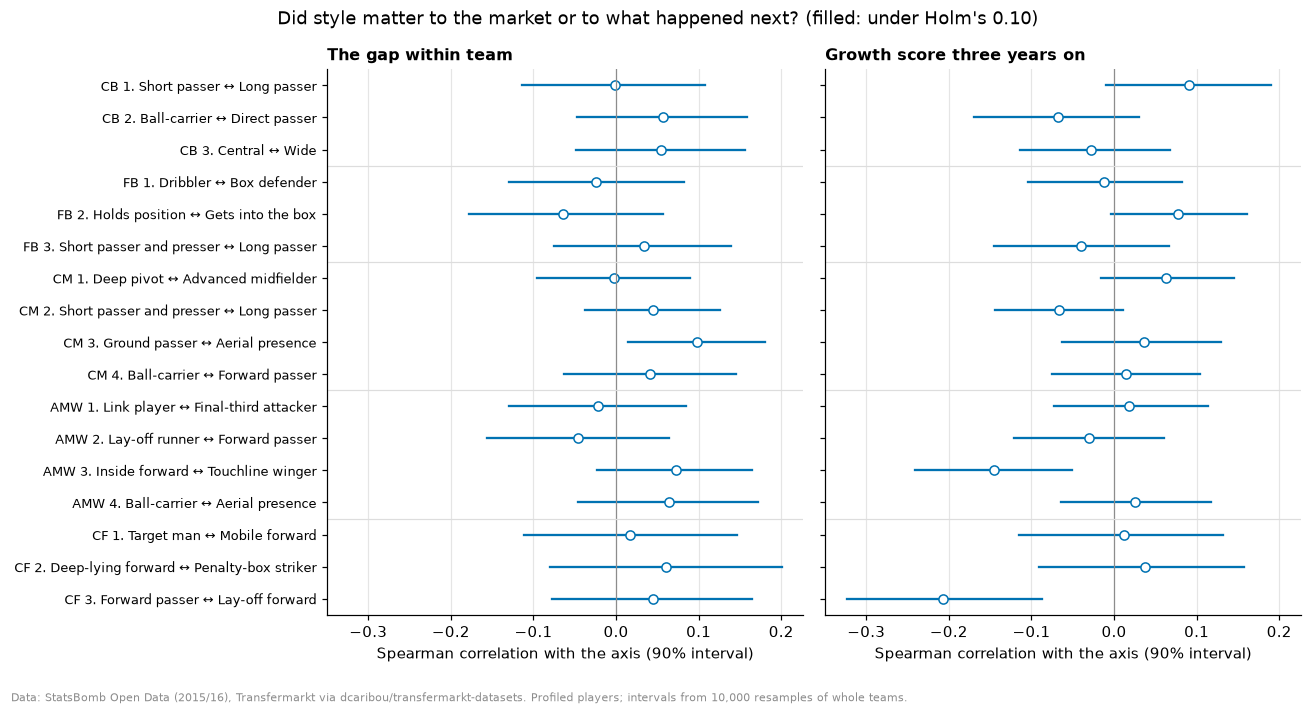

In [29]:
labels = [f"{g} {a}. {AXIS_NAMES[g, a][0]} ↔ {AXIS_NAMES[g, a][1]}" for g, a in AXIS_NAMES]
fig, axs = plt.subplots(1, 2, figsize=(12, 6.2), sharex=True, sharey=True)
for ax, q in zip(axs, QUESTIONS, strict=True):
    for i, (g, a) in enumerate(AXIS_NAMES):
        passed = adjusted_p[g, a, q] < 0.1
        ax.plot([low[g, a, q], high[g, a, q]], [i, i], color=OKABE_ITO[0], lw=1.5)
        ax.plot(point[g, a, q], i, "o", ms=6, color=OKABE_ITO[0],
                mfc=OKABE_ITO[0] if passed else "white")  # fmt: skip
    ax.axvline(0, color=GREY, lw=0.8)
    ax.set_title(QUESTIONS[q], fontsize=10.5)
    ax.set_xlabel("Spearman correlation with the axis (90% interval)")
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    starts = np.cumsum([AXES[g][0].loadings.shape[1] for g in AXES])[:-1] - 0.5
    for e in starts:
        ax.axhline(e, color="#DDDDDD", lw=0.8)
axs[0].set_yticks(range(len(labels)), labels, fontsize=8.5)
axs[0].set_ylim(len(labels) - 0.5, -0.5)
fig.suptitle("Did style matter to the market or to what happened next? (filled: under Holm's 0.10)")
fig.tight_layout()
credit(fig, CREDIT + ". Profiled players; intervals from 10,000 resamples of whole teams.")
plt.show()

In [30]:
# The axis that follows growth most closely, checked: at every horizon, by fifth of the axis, and
# beside minutes and the gap (score points from the bottom to the top of the group, each by rank).
g, a, _ = p.xs("score", level=2, drop_level=False).idxmin()
s = scores[g][a]
d = market[market.comparison_group == g].assign(style=s)
by_horizon = outcomes.pivot(index="player_id", columns="horizon", values="score").loc[d.index]
fifths = d.score.groupby(pd.qcut(d["style"], 5, labels=False)).mean()


def beside(rows):
    ranks = rows[["style", "minutes", "gap"]].rank(pct=True)
    X = np.column_stack([np.ones(len(rows)), ranks])
    return pd.Series(np.linalg.lstsq(X, rows.score, rcond=None)[0][1:], index=ranks.columns)


together = beside(d)
drawn = team_bootstrap(lambda rows: beside(d.iloc[rows]), d.team_id, draws=1000, seed=2016)
print(
    f"{GROUP_NAMES[g]}, axis {a} ({AXIS_NAMES[g, a][0].lower()} ↔ {AXIS_NAMES[g, a][1].lower()}): "
    "Spearman with the score at each horizon "
    + ", ".join(
        f"{h.year} {d['style'].corr(by_horizon[h], method='spearman'):+.2f}" for h in by_horizon
    )
    + "; mean score three years on by fifth of the axis (low end first) "
    + ", ".join(f"{v:.1f}" for v in fifths)
    + "; beside minutes and the gap: "
    + ", ".join(
        f"{k} {v:+.1f} ({drawn[k].quantile(0.05):+.1f} to {drawn[k].quantile(0.95):+.1f})"
        for k, v in together.items()
    )
    + f". The axis with age: {d['style'].corr(d.age, method='spearman'):+.2f}; with minutes: "
    f"{d['style'].corr(d.minutes, method='spearman'):+.2f}."
)

Centre-forwards, axis 3 (forward passer ↔ lay-off forward): Spearman with the score at each horizon 2017 -0.07, 2018 -0.17, 2019 -0.21, 2021 -0.21; mean score three years on by fifth of the axis (low end first) 57.1, 56.4, 49.3, 48.8, 38.7; beside minutes and the gap: style -21.4 (-34.0 to -8.3), minutes +14.8 (+2.5 to +27.3), gap +16.7 (+3.4 to +30.0). The axis with age: -0.27; with minutes: -0.01.


In [31]:
BUDGET, PLACES = 5e6, 5  # notebook 04's shortlists
FIFTHS = ["1 (weakest)", "2", "3", "4", "5 (strongest)"]
goal_difference = team_strength(con).set_index("team_id").goal_difference
market["team_fifth"] = market.team_id.map(
    pd.qcut(goal_difference.rank(method="first"), 5, labels=FIFTHS)
)
available = market[(market.value <= BUDGET) & (market.team_fifth != FIFTHS[-1])]
shortlist = available[pick_weights(available.gap, available.comparison_group, places=PLACES) > 0]
assert len(shortlist) == len(OUTFIELD) * PLACES
at_an_end, expected = 0, 0.0
for g, (axes, _, _) in AXES.items():
    regular_scores = scores[g].loc[fitted[g].index]
    ids = shortlist.index[shortlist.comparison_group == g]
    placed = pd.DataFrame(
        {
            f"{a}. {AXIS_NAMES[g, a][0]} ↔ {AXIS_NAMES[g, a][1]}": [
                100 * (regular_scores[a] < scores[g].loc[i, a]).mean() for i in ids
            ]
            for a in axes.loadings
        },
        index=pool.known_as.loc[ids].rename(None),
    )
    at_an_end += ((placed <= 10) | (placed >= 90)).any(axis=1).sum()
    expected += len(ids) * (1 - 0.8 ** placed.shape[1])
    placed["Minutes in the group's positions"] = minutes.loc[ids].to_numpy()
    placed["Score three years on"] = shortlist.score.loc[ids].to_numpy()
    on_axes = placed.columns[:-2]
    display(
        placed.style.format("{:.0f}").format("{:,.0f}", subset="Minutes in the group's positions")
        .background_gradient(cmap="PuOr", vmin=0, vmax=100, subset=on_axes)
        .set_caption(f"{GROUP_NAMES[g]} on the shortlists: percentile on each axis among the "
                     "group's regulars")
    )  # fmt: skip
print(
    f"Shortlisted players in the top or bottom tenth of at least one axis: {at_an_end} of "
    f"{len(shortlist)} (about {expected:.0f} if their places on the axes were drawn at random); "
    f"under 900 minutes in their group's positions, their scores pulled towards the middle: "
    f"{(minutes.loc[shortlist.index] < cfg.compared.minutes).sum()}."
)

,1. Short passer ↔ Long passer,2. Ball-carrier ↔ Direct passer,3. Central ↔ Wide,Minutes in the group's positions,Score three years on
Adama Soumaoro,4,52,27,"2,119",92
Issa Diop,76,72,58,"1,982",95
Sebastián Coates,78,92,80,"1,328",91
Pedro Bigas,14,3,46,"2,454",50
Adriano Russo,25,54,50,932,36


,1. Dribbler ↔ Box defender,2. Holds position ↔ Gets into the box,3. Short passer and presser ↔ Long passer,Minutes in the group's positions,Score three years on
Alexander Djiku,76,12,25,"1,450",95
Adam Smith,6,70,0,"2,086",94
Massimo Gobbi,52,20,49,"2,833",98
Cristiano Piccini,17,74,28,"1,481",99
Alassane Touré,6,62,26,993,43


,1. Deep pivot ↔ Advanced midfielder,2. Short passer and presser ↔ Long passer,3. Ground passer ↔ Aerial presence,4. Ball-carrier ↔ Forward passer,Minutes in the group's positions,Score three years on
Andrew Surman,19,88,65,65,"3,670",98
Lassana Coulibaly,69,36,79,12,726,56
Ellyes Joris Skhiri,25,52,70,64,557,97
Lorenzo Pellegrini,94,34,70,46,"1,206",95
Kevin Stewart,14,22,45,21,571,78


,1. Link player ↔ Final-third attacker,2. Lay-off runner ↔ Forward passer,3. Inside forward ↔ Touchline winger,4. Ball-carrier ↔ Aerial presence,Minutes in the group's positions,Score three years on
Jules Iloki,59,52,91,61,978,17
Ludovic Blas,34,79,58,70,462,79
Burgui,91,11,43,52,972,38
Momo,4,43,86,5,"1,285",73
Wanderson Maciel Sousa Campos,84,41,54,28,580,99


,1. Target man ↔ Mobile forward,2. Deep-lying forward ↔ Penalty-box striker,3. Forward passer ↔ Lay-off forward,Minutes in the group's positions,Score three years on
Souleymane Camara,60,17,19,"1,226",86
Billy Ketkeophomphone,81,3,36,"1,668",7
Roberto Inglese,39,72,66,"1,466",100
Duje Čop,54,24,57,"1,809",15
Josef Martínez,59,56,64,924,92


Shortlisted players in the top or bottom tenth of at least one axis: 10 of 25 (about 13 if their places on the axes were drawn at random); under 900 minutes in their group's positions, their scores pulled towards the middle: 5.


**The market did not pay for style beyond a player's numbers, and style barely told who would
grow.**

- Adding the axes to notebook 04's model of the value on 30 June 2016 explains no more of it in
  any group: out of sample the R² falls by 0.001 to 0.009 (from -0.014 to +0.003 on single
  splits). A player's age, minutes, league, team and profile already held whatever the market
  paid for style.
- No axis follows the gap within team beyond ±0.10: the market did not value one end of an axis
  further below its numbers than the other. The closest, central midfielders' aerial presence
  (+0.10, 90% interval +0.01 to +0.18), is far from Holm's threshold.
- None of the 34 correlations passes Holm's correction. Two stand out before it, both with growth:
  centre-forwards who lay the ball off grew less than those who pass it forward (-0.21, -0.32 to
  -0.09; Holm 0.16), touchline wingers less than inside forwards (-0.15, -0.24 to -0.05; Holm
  0.36).
- The centre-forwards' axis holds up short of the correction: it follows the score two, three
  and five years on (-0.17, -0.21, -0.21; -0.07 after one), the mean score falls from 57.1 in the
  fifth of forward passers to 38.7 in the fifth of lay-off forwards, and beside minutes and the
  gap it keeps 21 score points from one end of the group to the other (90% interval 8 to 34). As
  one of 34 correlations short of the correction, it is a lead to test, not a finding.

**The shortlists have no style in common.** The 25 players spread over their groups' axes: 10
stand in the top or bottom tenth of at least one, about as many as chance would put there (13).
Hits and misses do not split by style either: among centre-backs Soumaoro, a short passer, and
Coates, a long and direct passer, both scored over 90; among centre-forwards the misses
Ketkeophomphone and Čop sit near the middle of the third axis, as do the hits Inglese and
Martínez. Five of the 25 played under 900 minutes in their group's positions, so their places
are pulled towards the middle; with five players a group, this is description only.

### What section 4 shows

- **The market priced no style beyond a player's numbers and context**: the axes add nothing to
  the model of the value on 30 June 2016 (R² change -0.009 to -0.001), and none follows the gap
  within team beyond ±0.10.
- **Style did not tell who would grow**: no correlation with growth three years on passes Holm's
  correction over the 34. Centre-forwards who lay the ball off grew less than those who pass it
  forward (-0.21), steadily across horizons and beside minutes and the gap: a lead for the case
  study.
- **The shortlists span their groups' styles**: the back-test's picks were not a style in
  disguise.